# Poids des attributs dans l'indice de cyclabilité (bike index)

Adaptation de `analyse_poids_attributs.ipynb` (walk index, urbain / non urbain) à l'**indice de cyclabilité** du Grand Genève.

Ce notebook analyse le poids de chaque attribut :
- au sein de sa **classe** (attractivité, confort, équipement, infrastructure, sécurité),
- au sein du **bike index**.

Différences avec la version marche :
- **une seule layer** (`step3_aggregated_index_carreau200`) : le vélo n'est pas calculé en `GEO_WEIGHTING` urbain / non urbain. Le code accepte quand même plusieurs layers dans `LAYERS` (voir la config) ;
- **5 classes**, lues dans l'Excel, et colonnes `Classe_<classe>` dans le gpkg ;
- poids lus dans `attributs_info_bike_WIP.xlsx` (le fichier utilisé par `3_1_Compute_index`), en ne gardant que `include_in_index_GG == True` ;
- `3_1` calcule l'indice comme une **somme pondérée puis un min-max** (sans diviser par la somme des poids). L'indice du gpkg est donc une fonction **affine** de la moyenne pondérée reconstruite : on estime cette relation ($Y \approx \alpha + \beta\,\hat Y$) et on l'utilise pour que la décomposition de variance reste exacte ;
- une section 6 compare l'indice pondéré à `bike_index_unweighted`.

| # | Métrique | Question |
|---|---|---|
| 1 | Distribution (part de 0, part de 1, IQR, P5–P95, skew) | L'attribut a-t-il une plage de variation utile ? |
| 2 | Contribution moyenne $c_a = \tilde w_a\,x_a$ | De quoi est fait le score d'un carreau typique ? |
| 3 | Décomposition de variance $\mathrm{Cov}(\beta c_a, Y)/\mathrm{Var}(Y)$ | Qu'est-ce qui différencie les carreaux entre eux ? |
| 4 | Déficit $\tilde w_a\,(1-x_a)$ | Qu'est-ce qui fait perdre des points ? |
| 5 | Corrélation de Spearman | Lien monotone attribut ↔ classe / indice |
| 6 | Pondéré vs non pondéré | Que changent les poids par rapport à des poids égaux ? |

**Convention** : les attributs du gpkg sont normalisés dans [0, 1] et orientés « plus = mieux » (les attributs *défavorables* comme `pente`, `accident`, `vitesse_motorisee` sont inversés dans `3_1` — vérifié dans la cellule de contrôle).

In [28]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:.3f}".format)

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
NETWORK = "bike"
TERRITORY = "GG"


def find_repo_root(start=Path.cwd()):
    """Remonte jusqu'au dossier qui contient Data/ et Notebook/ (le notebook est dans Notebook/Step 4)."""
    for p in [start, *start.parents]:
        if (p / "Data").is_dir() and (p / "Notebook").is_dir():
            return p
    raise FileNotFoundError("Racine du dépôt introuvable : lancer le notebook depuis le dépôt")


REPO = find_repo_root()
STEP3_DIR = REPO / "Data" / "output" / NETWORK / TERRITORY / "step-3"
GPKG_PATH = STEP3_DIR / "step3_aggregated_index_carreau200.gpkg"
EXCEL_PATH = REPO / "Data" / "input" / "attributs" / f"attributs_info_{NETWORK}_WIP.xlsx"  # même fichier que 3_1_Compute_index
INCLUDE_COL = f"include_in_index_{TERRITORY}"

# Une entrée par layer à analyser. "class_col" : modèle du nom de colonne d'une classe ({cls} = nom de la classe dans l'Excel).
LAYERS = {
    TERRITORY: {
        "layer": "step3_aggregated_index_carreau200",
        "excel": EXCEL_PATH,
        "index_col": f"{NETWORK}_index",
        "class_col": "Classe_{cls}",
    },
    # Exemple si le vélo passe un jour en GEO_WEIGHTING urbain / non urbain :
    # "urban": {"layer": "step3_aggregated_index_carreau200_urban",
    #           "excel": REPO / "Data/input/attributs/attributs_info_bike_urbain.xlsx",
    #           "index_col": "bike_index_urban", "class_col": "{cls}_urban"},
}
UNWEIGHTED_COL = f"{NETWORK}_index_unweighted"   # section 6 (ignorée si la colonne n'existe pas)

OUT_DIR = REPO / "Data" / "output" / NETWORK / TERRITORY / "etude_stat"
OUT_DIR.mkdir(parents=True, exist_ok=True)

PALETTE = ["#2471a3", "#c0392b", "#27ae60", "#8e44ad"]
COLORS = {k: PALETTE[i % len(PALETTE)] for i, k in enumerate(LAYERS)}
print("gpkg :", GPKG_PATH.relative_to(REPO))
print("poids:", EXCEL_PATH.relative_to(REPO))

gpkg : Data/output/bike/GG/step-3/step3_aggregated_index_carreau200.gpkg
poids: Data/input/attributs/attributs_info_bike_WIP.xlsx


## 0. Chargement des layers et des poids

- Lecture des **attributs** de chaque layer sans la géométrie (rapide).
- Lecture des poids depuis l'onglet `attributs_info`, en ne gardant que les attributs `include_in_index_GG == True` (même filtre que `3_1`) :
  - `class_weight` → poids de l'attribut **dans sa classe**,
  - `initial_weight` → poids de l'attribut **dans le bike index**.
- Seuls les attributs présents dans le gpkg **et** de poids > 0 entrent dans les métriques 2 à 4. Les attributs à poids 0 (ex. `temperature`, `air`) restent visibles dans les métriques 1 et 5.
- Les **classes** sont celles de l'Excel, dans l'ordre du fichier.
- Contrôle NaN : toute ligne avec un NaN sur une colonne utilisée est signalée puis exclue.

In [29]:
def load_weights(xlsx_path, available_cols):
    w = pd.read_excel(xlsx_path, sheet_name="attributs_info")
    included = w[INCLUDE_COL].astype(str).str.strip().str.lower().eq("true")
    absent = sorted(set(w.loc[included, "attribute"]) - set(available_cols))
    if absent:
        print(f"   attributs inclus dans l'Excel mais absents du gpkg : {absent}")
    w = w[included & w["attribute"].isin(available_cols)].copy()
    w = w[["Class", "attribute", "initial_weight", "class_weight", "impact_attribut"]]
    w[["initial_weight", "class_weight"]] = w[["initial_weight", "class_weight"]].fillna(0.0).astype(float)
    return w.drop_duplicates("attribute").set_index("attribute")


def load_layer(key):
    cfg = LAYERS[key]
    gdf = gpd.read_file(GPKG_PATH, layer=cfg["layer"], ignore_geometry=True)
    weights = load_weights(cfg["excel"], gdf.columns)

    classes = list(dict.fromkeys(weights["Class"]))
    class_cols = {c: cfg["class_col"].format(cls=c) for c in classes}
    index_col = cfg["index_col"]
    attrs = list(weights.index)
    extra = [UNWEIGHTED_COL] if UNWEIGHTED_COL in gdf.columns else []
    used = attrs + list(class_cols.values()) + [index_col] + extra

    missing = [c for c in used if c not in gdf.columns]
    assert not missing, f"[{key}] colonnes absentes : {missing}"

    df = gdf[["GRID_ID"] + used].copy()
    df[used] = df[used].apply(pd.to_numeric, errors="coerce")
    nan_rows = df[used].isna().any(axis=1)
    print(f"[{key}] {len(df):,} carreaux | {len(attrs)} attributs | {len(classes)} classes | lignes avec NaN : {nan_rows.sum():,}")
    if nan_rows.any():
        print("   NaN par colonne :", df[used].isna().sum()[lambda s: s > 0].to_dict())
    df = df.loc[~nan_rows].reset_index(drop=True)

    return {"df": df, "weights": weights, "attrs": attrs, "classes": classes,
            "class_cols": class_cols, "index_col": index_col}


data = {k: load_layer(k) for k in LAYERS}
FIRST = next(iter(data))
CLASSES = list(dict.fromkeys(c for d in data.values() for c in d["classes"]))
print("Classes :", CLASSES)

[GG] 41,309 carreaux | 25 attributs | 5 classes | lignes avec NaN : 0
Classes : ['attractivite', 'confort', 'equipement', 'infrastructure', 'securite']


In [30]:
# Tableau des poids (une paire de colonnes par layer)
wcmp = pd.concat({k: d["weights"][["class_weight", "initial_weight"]] for k, d in data.items()}, axis=1)
wcmp.insert(0, "Class", pd.concat([d["weights"]["Class"] for d in data.values()]).groupby(level=0).first())
wcmp.insert(1, "impact", pd.concat([d["weights"]["impact_attribut"] for d in data.values()]).groupby(level=0).first())
wcmp = wcmp.loc[wcmp["Class"].map({c: i for i, c in enumerate(CLASSES)}).sort_values(kind="stable").index]
wcmp

Class       impact           GG               
                                                          class_weight initial_weight
attribute                                                                            
amenite                         attractivite    favorable        0.500          0.500
connectivite                    attractivite    favorable        0.500          0.500
pente                           attractivite  defavorable        0.500          0.500
eau                                  confort    favorable        0.500          0.500
temperature                          confort  defavorable        0.000          0.000
air                                  confort  defavorable        0.000          0.000
alentours                            confort    favorable        0.000          0.000
canopee                              confort    favorable        0.500          0.500
environnement_ouvert_naturel         confort    favorable        0.500          0.500
stationnement_velo                equipement    favorable        0.500          0.500
borne_reparation                  equipement    favorable        0.500          0.500
location                          equipement    favorable        0.500          0.500
sens_inverse                      equipement    favorable        0.500          0.500
service_velo                      equipement    favorable        0.500          0.500
parking_abris                     equipement    favorable        0.500          0.500
infra_cyclable                infrastructure    favorable        0.500          0.500
revetement                    infrastructure    favorable        0.500          0.500
giratoire                     infrastructure  defavorable        0.500          0.500
tourner_droite                infrastructure    favorable        0.500          0.500
traversees                    infrastructure    favorable        0.500          0.500
eclairage                           securite    favorable        0.500          0.500
vitesse_motorisee                   securite  defavorable        0.500          0.500
conflit_md                          securite  defavorable        0.500          0.500
accident                            securite  defavorable        0.500          0.500
charge                              securite  defavorable        0.500          0.500

In [31]:
# Contrôle d'orientation : un attribut 'defavorable' devrait déjà être inversé (corrélation > 0 avec sa classe)
rows = []
for k, d in data.items():
    df, w = d["df"], d["weights"]
    for a, r in w[w["class_weight"] > 0].iterrows():
        rho = stats.spearmanr(df[a], df[d["class_cols"][r["Class"]]]).statistic
        rows.append((k, a, r["Class"], r["impact_attribut"], rho))
chk = pd.DataFrame(rows, columns=["layer", "attribut", "classe", "impact", "spearman_avec_classe"])
print("Attributs défavorables avec corrélation négative à leur classe (non inversés ?) :")
display(chk[(chk.impact == "defavorable") & (chk.spearman_avec_classe < 0)])
print("Tous les attributs avec corrélation négative à leur classe :")
chk[chk.spearman_avec_classe < 0]

Attributs défavorables avec corrélation négative à leur classe (non inversés ?) :


,layer,attribut,classe,impact,spearman_avec_classe
14,GG,giratoire,infrastructure,defavorable,-0.011


Tous les attributs avec corrélation négative à leur classe :


,layer,attribut,classe,impact,spearman_avec_classe
14,GG,giratoire,infrastructure,defavorable,-0.011
16,GG,eclairage,securite,favorable,-0.209


In [32]:
# Attributs dont le poids diffère entre la classe et l'indice : ils ne pèsent pas pareil aux deux niveaux
for k, d in data.items():
    w = d["weights"]
    diff = w[(w["class_weight"] > 0) != (w["initial_weight"] > 0)]
    if len(diff):
        print(f"[{k}] attributs qui comptent dans un seul des deux niveaux :")
        display(diff)

### Reconstruction et fidélité

On reconstruit les scores à partir des attributs du carreau et des poids Excel :

$$\hat C_k = \frac{\sum_{a\in k} w^{class}_a\,x_a}{\sum_{a\in k} w^{class}_a}, \qquad \hat I = \frac{\sum_a w^{init}_a\,x_a}{\sum_a w^{init}_a}$$

Dans `3_1`, l'indice d'un tronçon est $\min\text{-}\max\big(\sum_a w_a x_a\big)$ : c'est une fonction **affine** de $\hat I$, et la moyenne par carreau (`3_2`, pondérée par la longueur) garde cette relation. On s'attend donc à $Y \approx \alpha + \beta\,\hat Y$ avec $\beta = \sum_a w_a / (\max - \min)$. On estime $\alpha$ et $\beta$ par régression pour chaque cible.

L'ajustement n'est pas parfait quand un attribut `keep_nan` (`pente`, `revetement`, `tourner_droite`, `vitesse_motorisee`, …) est manquant sur un tronçon : l'indice de ce tronçon est NaN et sort de la moyenne du carreau, alors que les autres attributs du tronçon y entrent. L'écart est mesuré ci-dessous et isolé dans le terme *résidu* de la métrique 3.

In [33]:
def build_contributions(d):
    """c_a = w̃_a * x_a (somme = score reconstruit, sur l'échelle des attributs)."""
    df, w = d["df"], d["weights"]
    out = {}
    for c in d["classes"]:
        wk = w[(w["Class"] == c) & (w["class_weight"] > 0)]["class_weight"]
        out[("class", c)] = (df[wk.index] * (wk / wk.sum()).values) if len(wk) else pd.DataFrame(index=df.index)
    wi = w[w["initial_weight"] > 0]["initial_weight"]
    out[("index", None)] = df[wi.index] * (wi / wi.sum()).values
    return out


def target_col(d, key):
    return d["index_col"] if key[0] == "index" else d["class_cols"][key[1]]


def calibrate(y, yhat):
    """Y ≈ alpha + beta * Ŷ (moindres carrés)."""
    beta, alpha = np.polyfit(yhat, y, 1)
    return alpha, beta


def fidelity(y, yhat, alpha, beta):
    yc = alpha + beta * yhat
    return {"pearson_r": np.corrcoef(y, yhat)[0, 1], "alpha": alpha, "beta": beta,
            "R2_calibre": 1 - ((y - yc) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            "MAE_calibre": (y - yc).abs().mean(),
            "MAE_brut (sans calibration)": (y - yhat).abs().mean()}


fid = []
for k, d in data.items():
    d["contrib"] = build_contributions(d)
    d["calib"] = {}
    for key, cb in d["contrib"].items():
        if not cb.shape[1]:
            continue
        y, yhat = d["df"][target_col(d, key)], cb.sum(axis=1)
        d["calib"][key] = calibrate(y, yhat)
        fid.append({"layer": k, "cible": key[1] or d["index_col"], **fidelity(y, yhat, *d["calib"][key])})
fid = pd.DataFrame(fid).set_index(["layer", "cible"])
fid

pearson_r  alpha  beta  R2_calibre  MAE_calibre  MAE_brut (sans calibration)
layer cible                                                                                       
GG    attractivite        1.000 -0.000 1.084       1.000        0.000                        0.020
      confort             1.000 -0.000 1.456       1.000        0.000                        0.121
      equipement          1.000 -0.000 1.818       1.000        0.000                        0.003
      infrastructure      0.999  0.000 1.000       0.999        0.000                        0.000
      securite            1.000 -0.000 1.000       1.000        0.000                        0.000
      bike_index          0.999 -0.204 2.121       0.998        0.000                        0.133

In [34]:
# Diagnostic : coefficients OLS bruts de chaque score du gpkg sur ses attributs.
# Avec le min-max de 3_1, la somme des coefficients doit être proche de beta (et non de 1) :
# une somme très différente de beta signale une formule différente du modèle "moyenne pondérée + affine".
rows = []
for k, d in data.items():
    for key, cb in d["contrib"].items():
        if not cb.shape[1]:
            continue
        X = d["df"][cb.columns].values; y = d["df"][target_col(d, key)].values
        b, *_ = np.linalg.lstsq(np.c_[X, np.ones(len(X))], y, rcond=None)
        rows.append({"layer": k, "cible": key[1] or d["index_col"], "n_attributs": cb.shape[1],
                     "somme_coefs": b[:-1].sum(), "beta_calibration": d["calib"][key][1], "constante": b[-1]})
pd.DataFrame(rows).set_index(["layer", "cible"])

n_attributs  somme_coefs  beta_calibration  constante
layer cible                                                                
GG    attractivite              3        1.084             1.084      0.000
      confort                   3        1.456             1.456     -0.000
      equipement                6        1.818             1.818     -0.000
      infrastructure            5        1.001             1.000      0.000
      securite                  5        1.000             1.000      0.000
      bike_index               22        2.125             2.121     -0.204

In [35]:
# Poids effectifs des classes dans l'indice (implicites via initial_weight)
cls_w = pd.DataFrame({
    k: d["weights"][d["weights"]["initial_weight"] > 0].groupby("Class")["initial_weight"].sum()
       .pipe(lambda s: s / s.sum()).reindex(CLASSES)
    for k, d in data.items()
})
cls_w.columns.name = "poids de la classe dans l'indice"
cls_w

poids de la classe dans l'indice,GG
Class,
attractivite,0.136
confort,0.136
equipement,0.273
infrastructure,0.227
securite,0.227


## 1. Distribution des attributs

- `%zero` / `%one` : part des carreaux à 0 ou saturés à 1. Un attribut avec 90 % de zéros ne peut quasiment pas différencier les carreaux (typique des équipements vélo ponctuels : stationnement, bornes, location…).
- `IQR`, `P5–P95` : plage de variation utile.
- `skew` : asymétrie (forte valeur positive = beaucoup de 0 et quelques pics → signe d'une normalisation par le max écrasée par des outliers).

In [36]:
def describe_attrs(d):
    df, w = d["df"], d["weights"]
    attrs = w.index
    X = df[attrs]
    return pd.DataFrame({
        "classe": w.loc[attrs, "Class"],
        "poids_classe": w.loc[attrs, "class_weight"],
        "poids_index": w.loc[attrs, "initial_weight"],
        "mean": X.mean(), "median": X.median(), "std": X.std(),
        "%zero": (X == 0).mean() * 100, "%one": (X == 1).mean() * 100,
        "IQR": X.quantile(.75) - X.quantile(.25),
        "P5-P95": X.quantile(.95) - X.quantile(.05),
        "skew": X.skew(),
    })


def class_order(index, ref):
    """Trie des attributs par classe (ordre de l'Excel) puis dans l'ordre de l'Excel."""
    w = data[ref]["weights"]
    pos = {a: i for i, a in enumerate(w.index)}
    cls = {c: i for i, c in enumerate(CLASSES)}
    return sorted(index, key=lambda a: (cls.get(w["Class"].get(a), 99), pos.get(a, 999)))


desc = {k: describe_attrs(d) for k, d in data.items()}
desc_cmp = pd.concat(desc, axis=1)
desc_cmp = desc_cmp.loc[class_order(desc_cmp.index, FIRST)]
desc_cmp

GG                                                                               
                                      classe poids_classe poids_index  mean median   std  %zero   %one   IQR P5-P95    skew
amenite                         attractivite        0.500       0.500 0.017  0.000 0.097 94.372  0.153 0.000  0.023   7.156
connectivite                    attractivite        0.500       0.500 0.140  0.120 0.074  0.065  0.000 0.091  0.206   1.822
pente                           attractivite        0.500       0.500 0.540  0.584 0.241  1.244  0.012 0.369  0.780  -0.523
eau                                  confort        0.500       0.500 0.028  0.000 0.139 93.764  0.833 0.000  0.112   5.560
temperature                          confort        0.000       0.000 0.301  0.153 0.355  4.725 19.236 0.219  1.000   1.315
air                                  confort        0.000       0.000 0.236  0.238 0.076  0.000  0.027 0.095  0.254  -0.179
alentours                            confort        0.000       0.000 0.467  0.364 0.420 16.287 24.084 0.975  1.000   0.190
canopee                              confort        0.500       0.500 0.453  0.396 0.343  6.800  1.716 0.674  0.963   0.231
environnement_ouvert_naturel         confort        0.500       0.500 0.312  0.194 0.330 29.841  0.131 0.592  0.918   0.616
stationnement_velo                equipement        0.500       0.500 0.006  0.000 0.048 97.337  0.017 0.000  0.000  10.782
borne_reparation                  equipement        0.500       0.500 0.000  0.000 0.014 99.801  0.005 0.000  0.000  41.030
location                          equipement        0.500       0.500 0.001  0.000 0.015 99.499  0.000 0.000  0.000  21.525
sens_inverse                      equipement        0.500       0.500 0.014  0.000 0.095 96.311  0.324 0.000  0.000   8.075
service_velo                      equipement        0.500       0.500 0.000  0.000 0.004 99.710  0.000 0.000  0.000  33.270
parking_abris                     equipement        0.500       0.500 0.001  0.000 0.009 99.300  0.000 0.000  0.000  25.416
infra_cyclable                infrastructure        0.500       0.500 0.215  0.300 0.166 20.497  0.479 0.253  0.434   0.871
revetement                    infrastructure        0.500       0.500 0.059  0.000 0.117 59.275  0.007 0.086  0.291   3.188
giratoire                     infrastructure        0.500       0.500 0.994  1.000 0.043  0.007 96.935 0.000  0.000 -10.244
tourner_droite                infrastructure        0.500       0.500 0.000  0.000 0.006 99.717  0.000 0.000  0.000  37.799
traversees                    infrastructure        0.500       0.500 0.772  0.814 0.230  1.022 26.307 0.300  0.700  -1.073
eclairage                           securite        0.500       0.500 0.055  0.000 0.195 89.155  1.377 0.000  0.549   3.745
vitesse_motorisee                   securite        0.500       0.500 0.634  0.944 0.423 17.807 45.995 0.854  1.000  -0.518
conflit_md                          securite        0.500       0.500 0.398  0.310 0.367 21.511 15.086 0.667  1.000   0.480
accident                            securite        0.500       0.500 0.980  1.000 0.097  0.058 89.811 0.000  0.106  -6.631
charge                              securite        0.500       0.500 0.988  1.000 0.058  0.034 84.776 0.000  0.070  -8.326

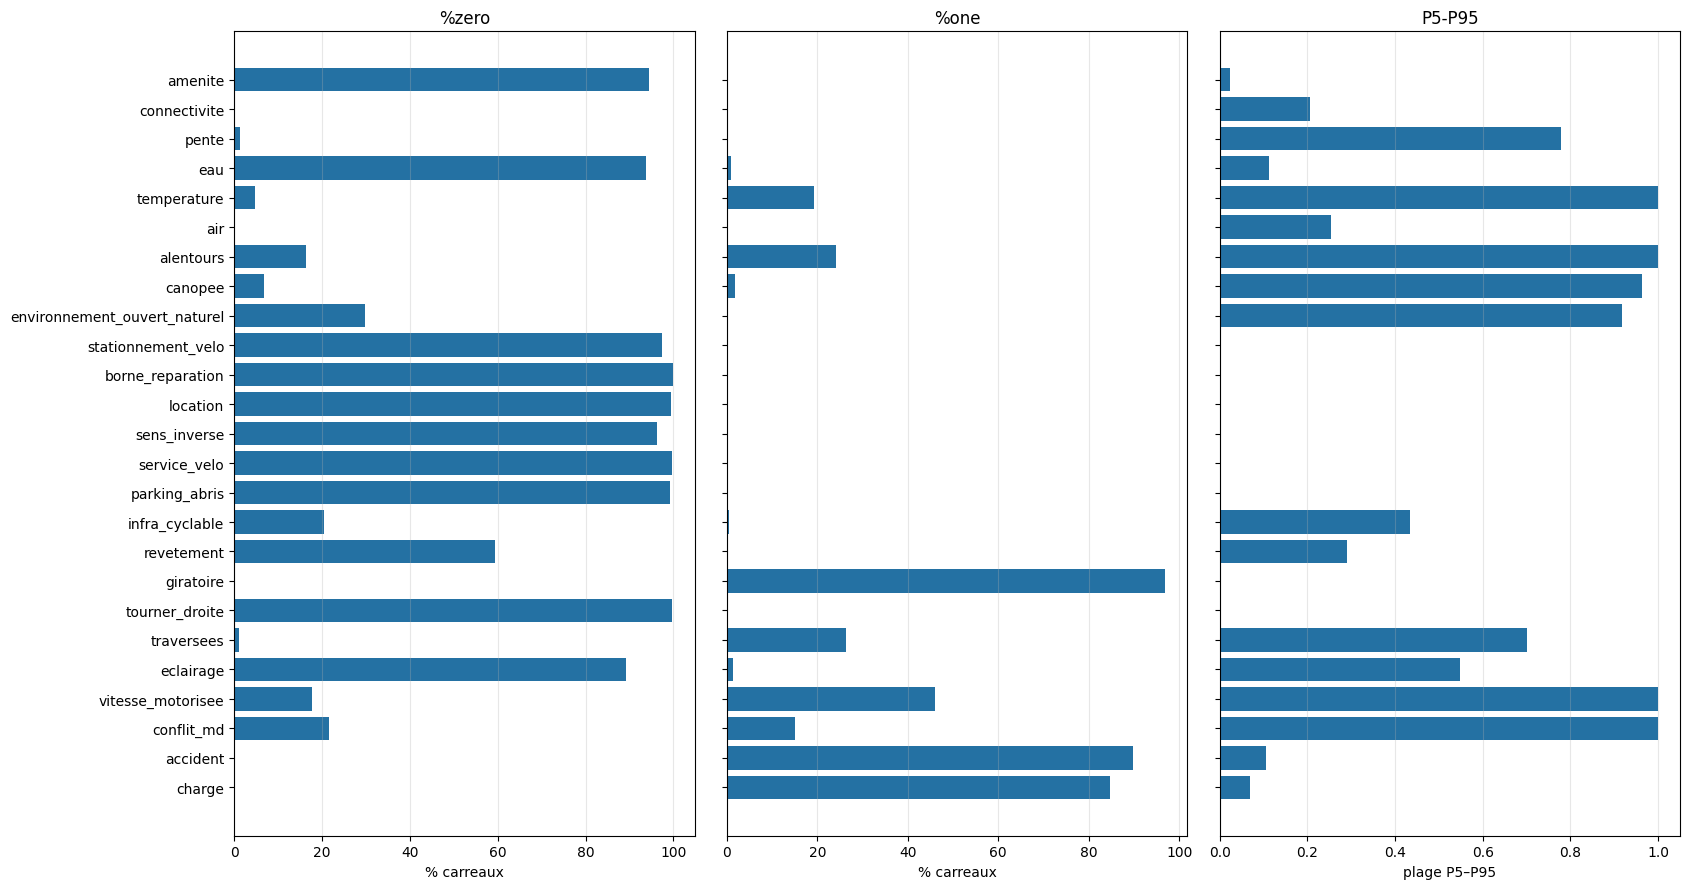

In [37]:
def grouped_barh(table, title, xlabel, ax=None, order=None):
    """table : index = attributs, colonnes = layers (une ou plusieurs)."""
    order = order if order is not None else table.index
    table = table.reindex(order)
    ax = ax or plt.gca()
    n = table.shape[1]; h = 0.8 / n
    y = np.arange(len(table))
    for i, k in enumerate(table.columns):
        ax.barh(y + (i - (n - 1) / 2) * h, table[k].values, height=h, label=k, color=COLORS.get(k))
    ax.set_yticks(y, table.index); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel(xlabel); ax.grid(axis="x", alpha=.3)
    if n > 1:
        ax.legend()
    return ax


def class_axes(n, ncols=3, size=(6, 5)):
    """Grille de sous-graphiques pour n classes (les cases en trop sont masquées)."""
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat[:n]


order_all = desc_cmp.index
fig, axes = plt.subplots(1, 3, figsize=(17, 9), sharey=True)
for ax, m, lab in zip(axes, ["%zero", "%one", "P5-P95"], ["% carreaux", "% carreaux", "plage P5–P95"]):
    grouped_barh(pd.DataFrame({k: desc[k][m] for k in data}), m, lab, ax=ax, order=order_all)
plt.tight_layout(); plt.savefig(OUT_DIR / "1_distribution.png", dpi=150); plt.show()

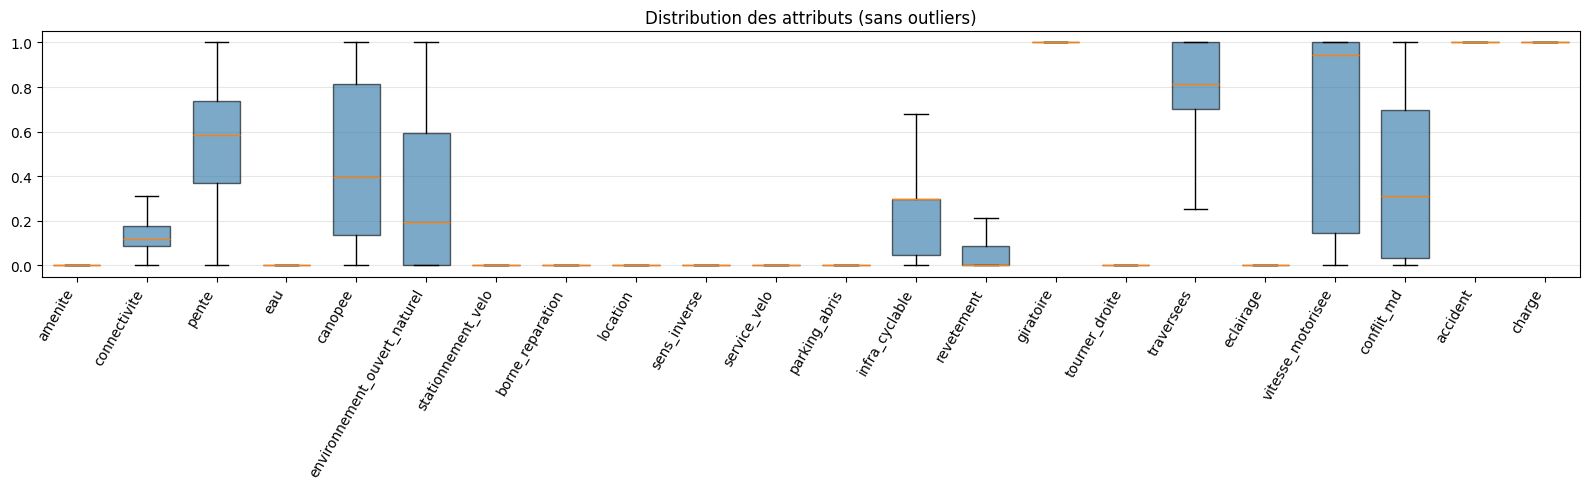

In [38]:
# Boxplots (attributs entrant dans l'indice d'au moins une layer)
attrs_box = [a for a in order_all
             if any(a in data[k]["weights"].index and data[k]["weights"].loc[a, "initial_weight"] > 0 for k in data)]
n = len(data); wbox = 0.8 / n
fig, ax = plt.subplots(figsize=(16, 5))
pos = np.arange(len(attrs_box))
for i, k in enumerate(data):
    vals = [data[k]["df"][a].values if a in data[k]["df"] else [] for a in attrs_box]
    bp = ax.boxplot(vals, positions=pos + (i - (n - 1) / 2) * wbox, widths=wbox * .85, patch_artist=True, showfliers=False)
    for b in bp["boxes"]: b.set_facecolor(COLORS[k]); b.set_alpha(.6)
ax.set_xticks(pos, attrs_box, rotation=60, ha="right")
if n > 1:
    ax.legend([plt.Rectangle((0, 0), 1, 1, color=COLORS[k], alpha=.6) for k in data], list(data))
ax.set_title("Distribution des attributs (sans outliers)"); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "1_boxplots.png", dpi=150); plt.show()

## 2. Contribution moyenne

$c_a = \tilde w_a \cdot x_a$ avec $\tilde w_a$ le poids normalisé (dans la classe ou dans l'indice). La part $\overline{c_a} / \sum_b \overline{c_b}$ dit de quoi est composé le score moyen (elle ne dépend pas de la calibration affine).

À comparer au **poids nominal** $\tilde w_a$ : un attribut qui pèse 10 % nominalement mais 0,5 % du score moyen est un attribut « mort » (presque toujours à 0).

In [39]:
def mean_contrib(contrib_df):
    m = contrib_df.mean()
    return pd.DataFrame({"contrib_moy": m, "part_%": m / m.sum() * 100})


def nominal_share(d, level, cls=None):
    w = d["weights"]
    if level == "index":
        s = w[w["initial_weight"] > 0]["initial_weight"]
    else:
        s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]
    return s / s.sum() * 100


# --- dans l'indice
rows = {}
for k, d in data.items():
    t = mean_contrib(d["contrib"][("index", None)])
    t["poids_nominal_%"] = nominal_share(d, "index")
    t["ratio_part/nominal"] = t["part_%"] / t["poids_nominal_%"]
    t["classe"] = d["weights"].loc[t.index, "Class"]
    rows[k] = t
m2_index = pd.concat(rows, axis=1)
m2_index = m2_index.loc[class_order(m2_index.index, FIRST)]
m2_index

GG                                                          
                             contrib_moy part_% poids_nominal_% ratio_part/nominal          classe
amenite                            0.001  0.258           4.545              0.057    attractivite
connectivite                       0.006  2.118           4.545              0.466    attractivite
pente                              0.025  8.167           4.545              1.797    attractivite
eau                                0.001  0.429           4.545              0.094         confort
canopee                            0.021  6.860           4.545              1.509         confort
environnement_ouvert_naturel       0.014  4.725           4.545              1.040         confort
stationnement_velo                 0.000  0.090           4.545              0.020      equipement
borne_reparation                   0.000  0.007           4.545              0.002      equipement
location                           0.000  0.013           4.545              0.003      equipement
sens_inverse                       0.001  0.211           4.545              0.046      equipement
service_velo                       0.000  0.002           4.545              0.000      equipement
parking_abris                      0.000  0.008           4.545              0.002      equipement
infra_cyclable                     0.010  3.252           4.545              0.715  infrastructure
revetement                         0.003  0.888           4.545              0.195  infrastructure
giratoire                          0.045 15.049           4.545              3.311  infrastructure
tourner_droite                     0.000  0.004           4.545              0.001  infrastructure
traversees                         0.035 11.690           4.545              2.572  infrastructure
eclairage                          0.003  0.834           4.545              0.183        securite
vitesse_motorisee                  0.029  9.594           4.545              2.111        securite
conflit_md                         0.018  6.027           4.545              1.326        securite
accident                           0.045 14.827           4.545              3.262        securite
charge                             0.045 14.945           4.545              3.288        securite

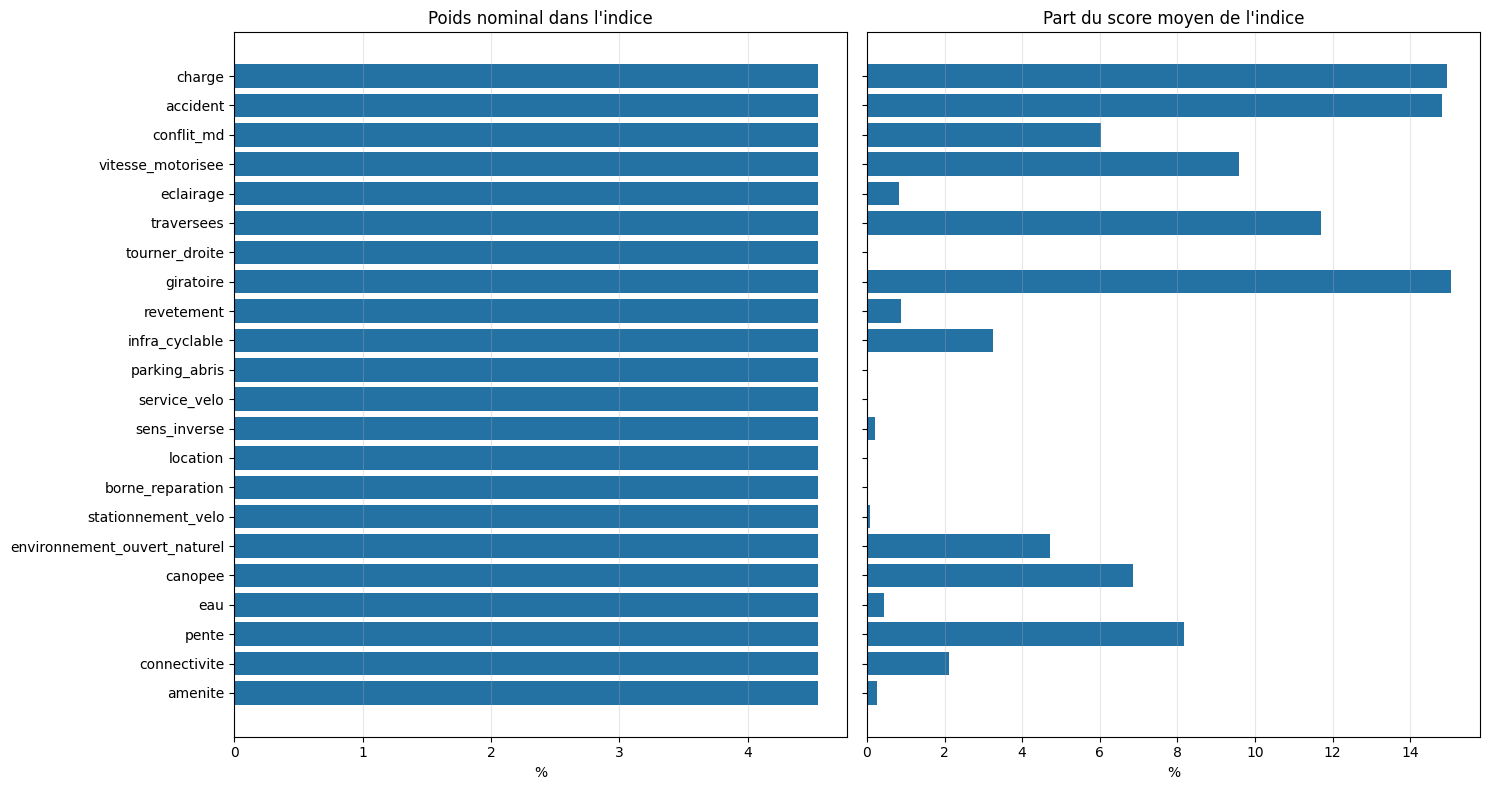

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
order_idx = m2_index.index
grouped_barh(pd.DataFrame({k: m2_index[(k, "poids_nominal_%")] for k in data}), "Poids nominal dans l'indice", "%", ax=axes[0], order=order_idx)
grouped_barh(pd.DataFrame({k: m2_index[(k, "part_%")] for k in data}), "Part du score moyen de l'indice", "%", ax=axes[1], order=order_idx)
plt.tight_layout(); plt.savefig(OUT_DIR / "2_contrib_index.png", dpi=150); plt.show()

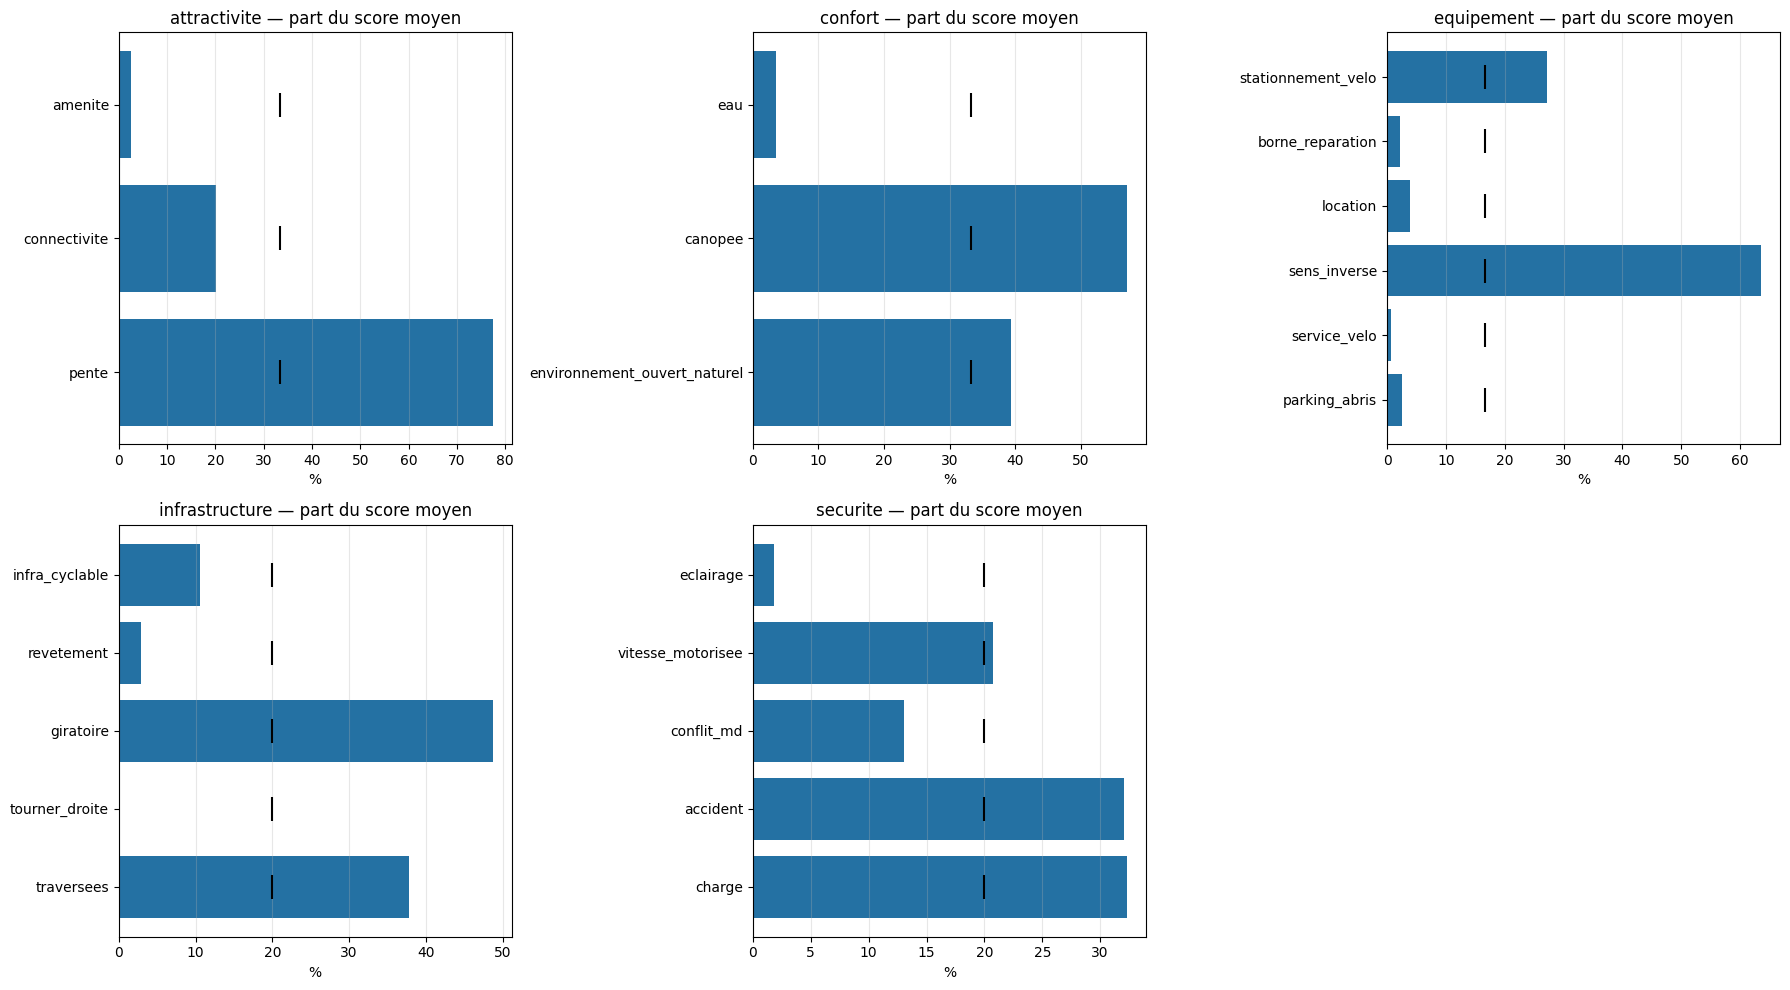

Trait noir = poids nominal de l'attribut dans la classe.

=== attractivite ===


GG                       
             contrib_moy part_% poids_nominal_%
amenite            0.006  2.446          33.333
connectivite       0.047 20.089          33.333
pente              0.180 77.465          33.333


=== confort ===


GG                       
                             contrib_moy part_% poids_nominal_%
eau                                0.009  3.573          33.333
canopee                            0.151 57.098          33.333
environnement_ouvert_naturel       0.104 39.328          33.333


=== equipement ===


GG                       
                   contrib_moy part_% poids_nominal_%
stationnement_velo       0.001 27.181          16.667
borne_reparation         0.000  2.139          16.667
location                 0.000  3.908          16.667
sens_inverse             0.002 63.587          16.667
service_velo             0.000  0.670          16.667
parking_abris            0.000  2.514          16.667


=== infrastructure ===


GG                       
               contrib_moy part_% poids_nominal_%
infra_cyclable       0.043 10.530          20.000
revetement           0.012  2.875          20.000
giratoire            0.199 48.729          20.000
tourner_droite       0.000  0.012          20.000
traversees           0.154 37.854          20.000


=== securite ===


GG                       
                  contrib_moy part_% poids_nominal_%
eclairage               0.011  1.804          20.000
vitesse_motorisee       0.127 20.754          20.000
conflit_md              0.080 13.038          20.000
accident                0.196 32.074          20.000
charge                  0.198 32.329          20.000

In [41]:
# --- dans chaque classe
m2_class = {}
fig, axes = class_axes(len(CLASSES))
for ax, c in zip(axes, CLASSES):
    t = {}
    for k, d in data.items():
        cb = d["contrib"].get(("class", c), pd.DataFrame())
        if cb.shape[1]:
            tt = mean_contrib(cb); tt["poids_nominal_%"] = nominal_share(d, "class", c); t[k] = tt
    m2_class[c] = pd.concat(t, axis=1)
    tab = pd.DataFrame({k: m2_class[c][(k, "part_%")] for k in t})
    nom = pd.DataFrame({k: m2_class[c][(k, "poids_nominal_%")] for k in t})
    grouped_barh(tab, f"{c} — part du score moyen", "%", ax=ax)
    # repère : poids nominal (première layer)
    ax.scatter(nom.iloc[:, 0].reindex(tab.index).values, np.arange(len(tab)), marker="|", s=300, color="k", zorder=3, label="poids nominal")
plt.tight_layout(); plt.savefig(OUT_DIR / "2_contrib_classes.png", dpi=150); plt.show()
print("Trait noir = poids nominal de l'attribut dans la classe.")
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m2_class[c])

## 3. Décomposition de variance

Pour une cible $Y$ (score de classe ou bike index **tels que dans le gpkg**), avec $\alpha, \beta$ estimés plus haut :

$$\mathrm{Var}(Y) = \sum_a \mathrm{Cov}(\beta\,c_a, Y) + \mathrm{Cov}(\varepsilon, Y), \qquad \varepsilon = Y - \alpha - \beta\sum_a c_a$$

La part $\mathrm{Cov}(\beta c_a, Y)/\mathrm{Var}(Y)$ dit **quel attribut explique les différences entre carreaux**. Les parts somment exactement à 100 % (résidu inclus). Une part peut être négative si l'attribut varie à contre-sens du reste de l'indice.

On ajoute les **poids effectifs** : coefficients d'une régression linéaire de $Y$ sur les attributs, ramenés en %. S'ils s'écartent des poids nominaux, la formule réelle diffère du modèle simple (typiquement à cause des attributs `keep_nan`).

In [42]:
def variance_decomp(contrib_df, y, alpha=0.0, beta=1.0):
    var = y.var()
    shares = contrib_df.apply(lambda c: np.cov(beta * c, y)[0, 1]) / var * 100
    resid = y - alpha - beta * contrib_df.sum(axis=1)
    shares["(résidu)"] = np.cov(resid, y)[0, 1] / var * 100
    return shares


def effective_weights(X, y):
    A = np.c_[X.values, np.ones(len(X))]
    b, *_ = np.linalg.lstsq(A, y.values, rcond=None)
    coef = pd.Series(b[:-1], index=X.columns)
    return coef / coef.sum() * 100


m3 = {}
for k, d in data.items():
    y = d["df"][d["index_col"]]
    cb = d["contrib"][("index", None)]
    m3[k] = pd.DataFrame({
        "part_variance_%": variance_decomp(cb, y, *d["calib"][("index", None)]),
        "poids_nominal_%": nominal_share(d, "index"),
        "poids_effectif_OLS_%": effective_weights(d["df"][cb.columns], y),
    })
m3_index = pd.concat(m3, axis=1)
m3_index = m3_index.loc[class_order([a for a in m3_index.index if a != "(résidu)"], FIRST) + ["(résidu)"]]
m3_index

GG                                     
                             part_variance_% poids_nominal_% poids_effectif_OLS_%
amenite                                0.619           4.545                4.537
connectivite                          -2.648           4.545                4.537
pente                                  3.352           4.545                4.535
eau                                    2.939           4.545                4.526
canopee                                7.406           4.545                4.540
environnement_ouvert_naturel           5.455           4.545                4.543
stationnement_velo                     0.466           4.545                4.510
borne_reparation                       0.049           4.545                4.595
location                               0.014           4.545                4.602
sens_inverse                           1.388           4.545                4.546
service_velo                           0.010           4.545                4.468
parking_abris                          0.036           4.545                4.597
infra_cyclable                        11.021           4.545                4.537
revetement                            -1.325           4.545                4.557
giratoire                              0.470           4.545                4.548
tourner_droite                         0.016           4.545                4.617
traversees                             6.266           4.545                4.541
eclairage                              0.342           4.545                4.528
vitesse_motorisee                     37.068           4.545                4.540
conflit_md                            25.732           4.545                4.538
accident                               0.407           4.545                4.536
charge                                 0.734           4.545                4.523
(résidu)                               0.183             NaN                  NaN

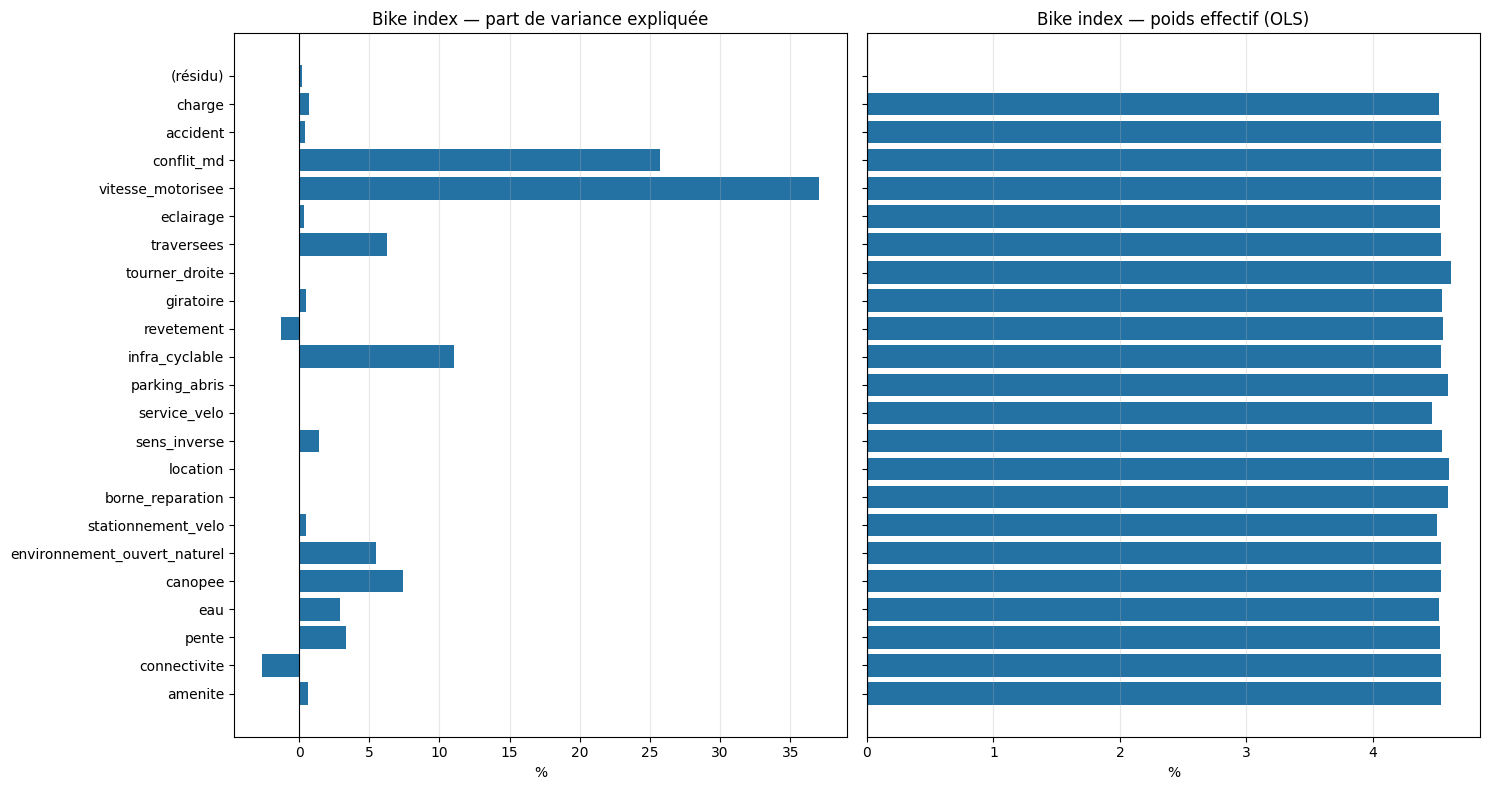

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
order3 = m3_index.index
grouped_barh(pd.DataFrame({k: m3_index[(k, "part_variance_%")] for k in data}), "Bike index — part de variance expliquée", "%", ax=axes[0], order=order3)
grouped_barh(pd.DataFrame({k: m3_index[(k, "poids_effectif_OLS_%")] for k in data}), "Bike index — poids effectif (OLS)", "%", ax=axes[1], order=order3)
for ax in axes: ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT_DIR / "3_variance_index.png", dpi=150); plt.show()

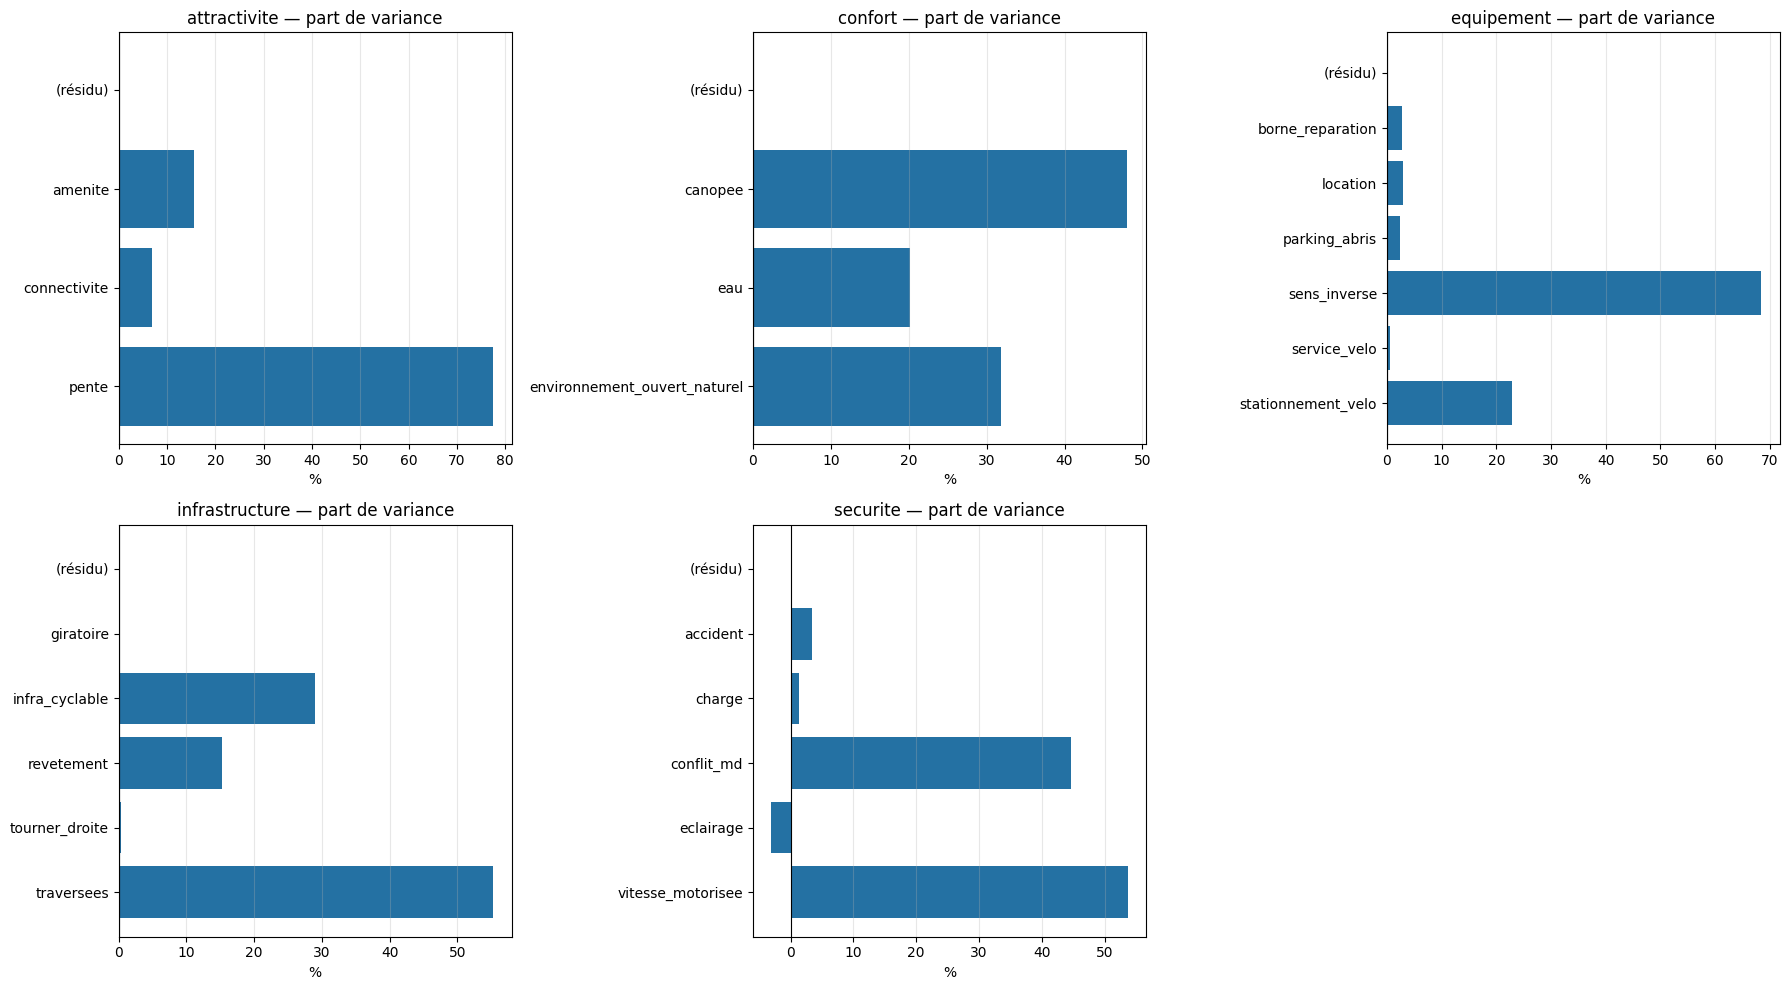


=== attractivite ===


GG                                     
             part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)               0.000             NaN                  NaN
amenite               15.595          33.333               33.333
connectivite           6.931          33.333               33.333
pente                 77.474          33.333               33.333


=== confort ===


GG                                     
                             part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                               0.000             NaN                  NaN
canopee                               48.034          33.333               33.333
eau                                   20.117          33.333               33.333
environnement_ouvert_naturel          31.849          33.333               33.333


=== equipement ===


GG                                     
                   part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                     0.000             NaN                  NaN
borne_reparation             2.687          16.667               16.668
location                     2.996          16.667               16.666
parking_abris                2.415          16.667               16.667
sens_inverse                68.446          16.667               16.666
service_velo                 0.516          16.667               16.668
stationnement_velo          22.941          16.667               16.666


=== infrastructure ===


GG                                     
               part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                 0.117             NaN                  NaN
giratoire                0.177          20.000               19.959
infra_cyclable          28.942          20.000               19.971
revetement              15.235          20.000               19.992
tourner_droite           0.277          20.000               20.101
traversees              55.251          20.000               19.976


=== securite ===


GG                                     
                  part_variance_% poids_nominal_% poids_effectif_OLS_%
(résidu)                    0.000             NaN                  NaN
accident                    3.394          20.000               20.000
charge                      1.403          20.000               20.000
conflit_md                 44.643          20.000               20.000
eclairage                  -3.176          20.000               20.000
vitesse_motorisee          53.735          20.000               20.000

In [44]:
# Variance par classe : attributs -> classe
m3_class = {}
fig, axes = class_axes(len(CLASSES))
for ax, c in zip(axes, CLASSES):
    t = {}
    for k, d in data.items():
        cb = d["contrib"].get(("class", c), pd.DataFrame())
        if cb.shape[1]:
            y = d["df"][d["class_cols"][c]]
            t[k] = pd.DataFrame({"part_variance_%": variance_decomp(cb, y, *d["calib"][("class", c)]),
                                 "poids_nominal_%": nominal_share(d, "class", c),
                                 "poids_effectif_OLS_%": effective_weights(d["df"][cb.columns], y)})
    m3_class[c] = pd.concat(t, axis=1)
    grouped_barh(pd.DataFrame({k: m3_class[c][(k, "part_variance_%")] for k in t}), f"{c} — part de variance", "%", ax=ax)
    ax.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.savefig(OUT_DIR / "3_variance_classes.png", dpi=150); plt.show()
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m3_class[c])

### 3 bis. Covariances des attributs au sein de chaque classe

Pour chaque classe :
- **matrice de covariance brute** $\mathrm{Cov}(x_a, x_b)$ des attributs de la classe ;
- **matrice de contribution à la variance** $M_{ab} = \beta^2\,\tilde w_a \tilde w_b\,\mathrm{Cov}(x_a, x_b) / \mathrm{Var}(Y)$ en %, avec $Y$ le score de classe du gpkg. La **diagonale** est l'effet propre de chaque attribut, les **hors-diagonales** sont les effets de covariance (rouge = renforcement, bleu = compensation). La somme d'une ligne + le résidu = part de variance de l'attribut (métrique 3) ;
- tableau **effet propre / covariance avec les autres / résidu / total**.

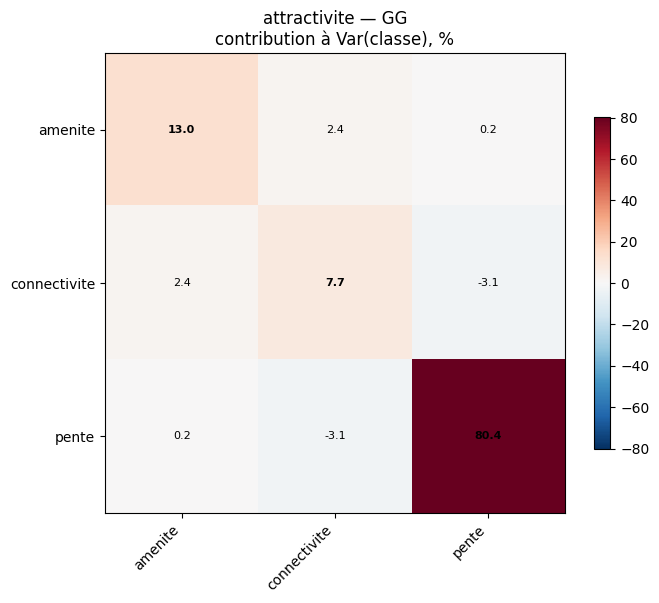


=== attractivite — GG : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
amenite,13.049,2.547,-0.000,15.595
connectivite,7.675,-0.744,-0.000,6.931
pente,80.378,-2.905,0.000,77.474


--- attractivite — GG : covariance brute ---


,amenite,connectivite,pente
amenite,0.0094,0.0017,0.0001
connectivite,0.0017,0.0055,-0.0022
pente,0.0001,-0.0022,0.0579


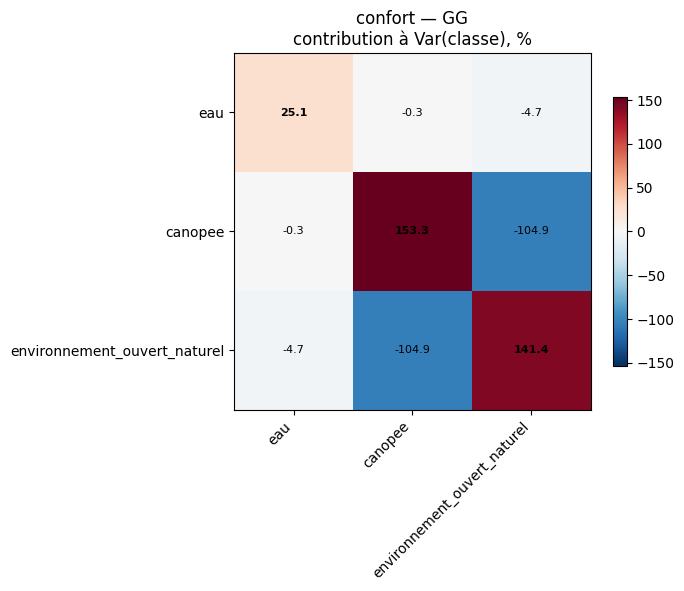


=== confort — GG : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
eau,25.071,-4.954,-0.000,20.117
canopee,153.256,-105.221,-0.001,48.034
environnement_ouvert_naturel,141.449,-109.601,0.001,31.849


--- confort — GG : covariance brute ---


,eau,canopee,environnement_ouvert_naturel
eau,0.0193,-0.0002,-0.0036
canopee,-0.0002,0.1178,-0.0807
environnement_ouvert_naturel,-0.0036,-0.0807,0.1087


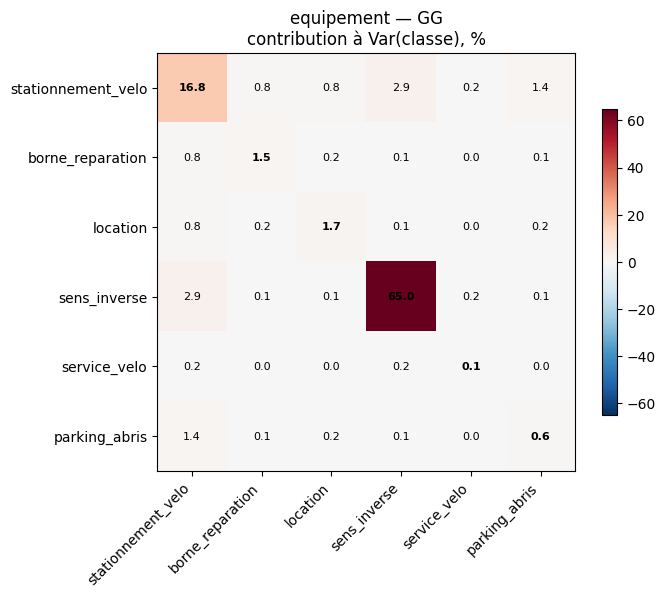


=== equipement — GG : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
stationnement_velo,16.773,6.167,0.000,22.941
borne_reparation,1.458,1.229,0.000,2.687
location,1.696,1.300,0.000,2.996
sens_inverse,65.017,3.430,-0.001,68.446
service_velo,0.094,0.422,0.000,0.516
parking_abris,0.616,1.799,0.000,2.415


--- equipement — GG : covariance brute ---


,stationnement_velo,borne_reparation,location,sens_inverse,service_velo,parking_abris
stationnement_velo,0.0023,0.0001,0.0001,0.0004,0.0000,0.0002
borne_reparation,0.0001,0.0002,0.0000,0.0000,0.0000,0.0000
location,0.0001,0.0000,0.0002,0.0000,0.0000,0.0000
sens_inverse,0.0004,0.0000,0.0000,0.0090,0.0000,0.0000
service_velo,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
parking_abris,0.0002,0.0000,0.0000,0.0000,0.0000,0.0001


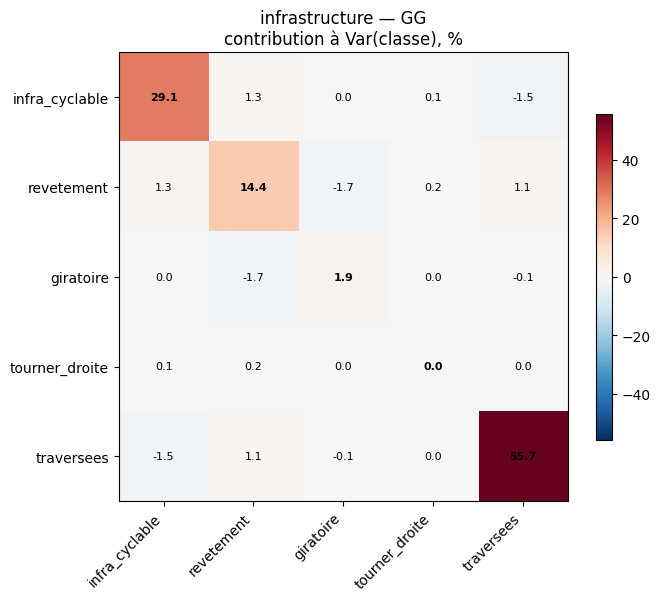


=== infrastructure — GG : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
infra_cyclable,29.094,-0.144,-0.007,28.942
revetement,14.396,0.827,0.013,15.235
giratoire,1.927,-1.746,-0.003,0.177
tourner_droite,0.044,0.233,0.000,0.277
traversees,55.705,-0.451,-0.003,55.251


--- infrastructure — GG : covariance brute ---


,infra_cyclable,revetement,giratoire,tourner_droite,traversees
infra_cyclable,0.0276,0.0012,0.0000,0.0001,-0.0014
revetement,0.0012,0.0137,-0.0016,0.0001,0.0011
giratoire,0.0000,-0.0016,0.0018,0.0000,-0.0001
tourner_droite,0.0001,0.0001,0.0000,0.0000,0.0000
traversees,-0.0014,0.0011,-0.0001,0.0000,0.0528


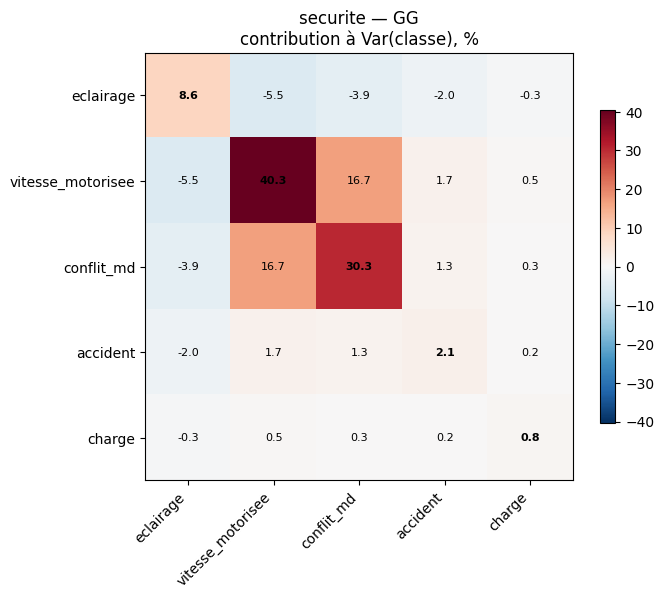


=== securite — GG : décomposition ===


,effet_propre_%,covariance_autres_%,residu_%,total_%
attribute,,,,
eclairage,8.553,-11.729,-0.000,-3.176
vitesse_motorisee,40.327,13.409,0.000,53.735
conflit_md,30.312,14.331,0.000,44.643
accident,2.109,1.286,0.000,3.394
charge,0.750,0.653,-0.000,1.403


--- securite — GG : covariance brute ---


,eclairage,vitesse_motorisee,conflit_md,accident,charge
eclairage,0.0380,-0.0244,-0.0174,-0.0088,-0.0015
vitesse_motorisee,-0.0244,0.1791,0.0740,0.0077,0.0022
conflit_md,-0.0174,0.0740,0.1346,0.0058,0.0012
accident,-0.0088,0.0077,0.0058,0.0094,0.0010
charge,-0.0015,0.0022,0.0012,0.0010,0.0033


In [45]:
def class_cov_decomp(d, cls):
    w = d["weights"]
    s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]
    if not len(s):
        return None
    alpha, beta = d["calib"][("class", cls)]
    wn = s / s.sum()
    X = d["df"][s.index]
    y = d["df"][d["class_cols"][cls]]
    var_y = y.var()
    cov = X.cov()
    M = cov * np.outer(wn, wn) * beta ** 2 / var_y * 100
    resid = y - alpha - beta * (X * wn.values).sum(axis=1)
    res = pd.Series({a: beta * wn[a] * np.cov(X[a], resid)[0, 1] / var_y * 100 for a in s.index})
    table = pd.DataFrame({
        "effet_propre_%": np.diag(M),
        "covariance_autres_%": M.sum(axis=1) - np.diag(M),
        "residu_%": res,
    }, index=s.index)
    table["total_%"] = table.sum(axis=1)
    return {"cov": cov, "corr": X.corr(), "M": M, "table": table}


def plot_matrix(ax, M, title, fmt="{:.1f}"):
    lim = np.nanmax(np.abs(M.values)) or 1
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_xticks(range(len(M)), M.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(M)), M.index)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M.iat[i, j]), ha="center", va="center", fontsize=8,
                    fontweight="bold" if i == j else "normal")
    ax.set_title(title)
    return im


cov_results = {}
for c in CLASSES:
    res = {k: class_cov_decomp(d, c) for k, d in data.items() if c in d["classes"]}
    res = {k: v for k, v in res.items() if v is not None and len(v["M"]) > 1}
    cov_results[c] = res
    if not res:
        print(f"{c} : un seul attribut, pas de covariance à afficher.")
        continue
    fig, axes = plt.subplots(1, len(res), figsize=(7 * len(res), 6), squeeze=False)
    for ax, (k, r) in zip(axes[0], res.items()):
        im = plot_matrix(ax, r["M"], f"{c} — {k}\ncontribution à Var(classe), %")
        fig.colorbar(im, ax=ax, shrink=.7)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"3bis_covariance_{c}.png", dpi=150); plt.show()
    for k, r in res.items():
        print(f"\n=== {c} — {k} : décomposition ===")
        display(r["table"])
        print(f"--- {c} — {k} : covariance brute ---")
        display(r["cov"].style.format("{:.4f}").background_gradient(cmap="RdBu_r", axis=None))

### 3 ter. Classes → bike index

Contribution de chaque **score de classe du gpkg** à la variance de l'indice. Attention : les classes sont min-maxées séparément dans `3_1`, et pour le vélo `class_weight` ≠ `initial_weight` pour certains attributs (ex. `connectivite`, `pente`). L'indice n'est donc pas exactement une combinaison des classes : on calibre $Y \approx \alpha + \beta \sum_k \pi_k C_k$ ($\pi_k$ = poids de la classe) et l'écart passe dans le résidu.

In [46]:
rows = {}
for k, d in data.items():
    y = d["df"][d["index_col"]]
    cls_k = [c for c in CLASSES if c in d["classes"] and pd.notna(cls_w.loc[c, k])]
    Cdf = pd.DataFrame({c: d["df"][d["class_cols"][c]] * cls_w.loc[c, k] for c in cls_k})
    a, b = calibrate(y, Cdf.sum(axis=1))
    rows[k] = pd.DataFrame({"poids_nominal_%": cls_w[k] * 100,
                            "part_variance_%": variance_decomp(Cdf, y, a, b),
                            "poids_effectif_OLS_%": effective_weights(d["df"][[d["class_cols"][c] for c in cls_k]].set_axis(cls_k, axis=1), y)})
m3_classes_to_index = pd.concat(rows, axis=1)
m3_classes_to_index

GG                                     
               poids_nominal_% part_variance_% poids_effectif_OLS_%
(résidu)                   NaN           2.184                  NaN
attractivite            13.636           1.291               15.238
confort                 13.636          20.686               11.366
equipement              27.273           3.208               18.203
infrastructure          22.727          14.813               27.624
securite                22.727          57.817               27.569

## 4. Déficit (manque à gagner)

$d_a = \tilde w_a\,(1 - x_a)$ : ce que l'attribut fait perdre par rapport à un carreau parfait (tous les attributs à 1). La somme des $d_a$ vaut $1-\hat I$ (échelle de la moyenne pondérée, avant min-max ; les parts en % ne dépendent pas de cette échelle).

Calculé sur **tous les carreaux** et sur le **quartile inférieur** de l'indice (les carreaux les moins bien notés), pour voir ce qui tire spécifiquement vers le bas.

In [47]:
def deficit_table(d, level="index", cls=None):
    w = d["weights"]; df = d["df"]
    if level == "index":
        s = w[w["initial_weight"] > 0]["initial_weight"]; y = df[d["index_col"]]
    else:
        s = w[(w["Class"] == cls) & (w["class_weight"] > 0)]["class_weight"]; y = df[d["class_cols"][cls]]
    if not len(s):
        return None
    D = (1 - df[s.index]) * (s / s.sum()).values
    q1 = y <= y.quantile(.25)
    return pd.DataFrame({
        "deficit_moy": D.mean(), "part_deficit_%": D.mean() / D.mean().sum() * 100,
        "deficit_moy_Q1": D[q1].mean(), "part_deficit_Q1_%": D[q1].mean() / D[q1].mean().sum() * 100,
    })


m4_index = pd.concat({k: deficit_table(d) for k, d in data.items()}, axis=1)
m4_index = m4_index.loc[class_order(m4_index.index, FIRST)]
m4_index

GG                                                
                             deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
amenite                            0.045          6.386          0.045             5.974
connectivite                       0.039          5.588          0.038             5.049
pente                              0.021          2.991          0.021             2.741
eau                                0.044          6.312          0.045             6.008
canopee                            0.025          3.552          0.029             3.907
environnement_ouvert_naturel       0.031          4.468          0.034             4.569
stationnement_velo                 0.045          6.458          0.045             6.042
borne_reparation                   0.045          6.494          0.045             6.058
location                           0.045          6.491          0.045             6.053
sens_inverse                       0.045          6.406          0.045             6.038
service_velo                       0.045          6.496          0.045             6.059
parking_abris                      0.045          6.493          0.045             6.058
infra_cyclable                     0.036          5.101          0.042             5.600
revetement                         0.043          6.116          0.042             5.596
giratoire                          0.000          0.036          0.001             0.069
tourner_droite                     0.045          6.495          0.045             6.059
traversees                         0.010          1.478          0.012             1.590
eclairage                          0.043          6.139          0.043             5.786
vitesse_motorisee                  0.017          2.378          0.039             5.180
conflit_md                         0.027          3.909          0.040             5.272
accident                           0.001          0.132          0.001             0.165
charge                             0.001          0.081          0.001             0.128

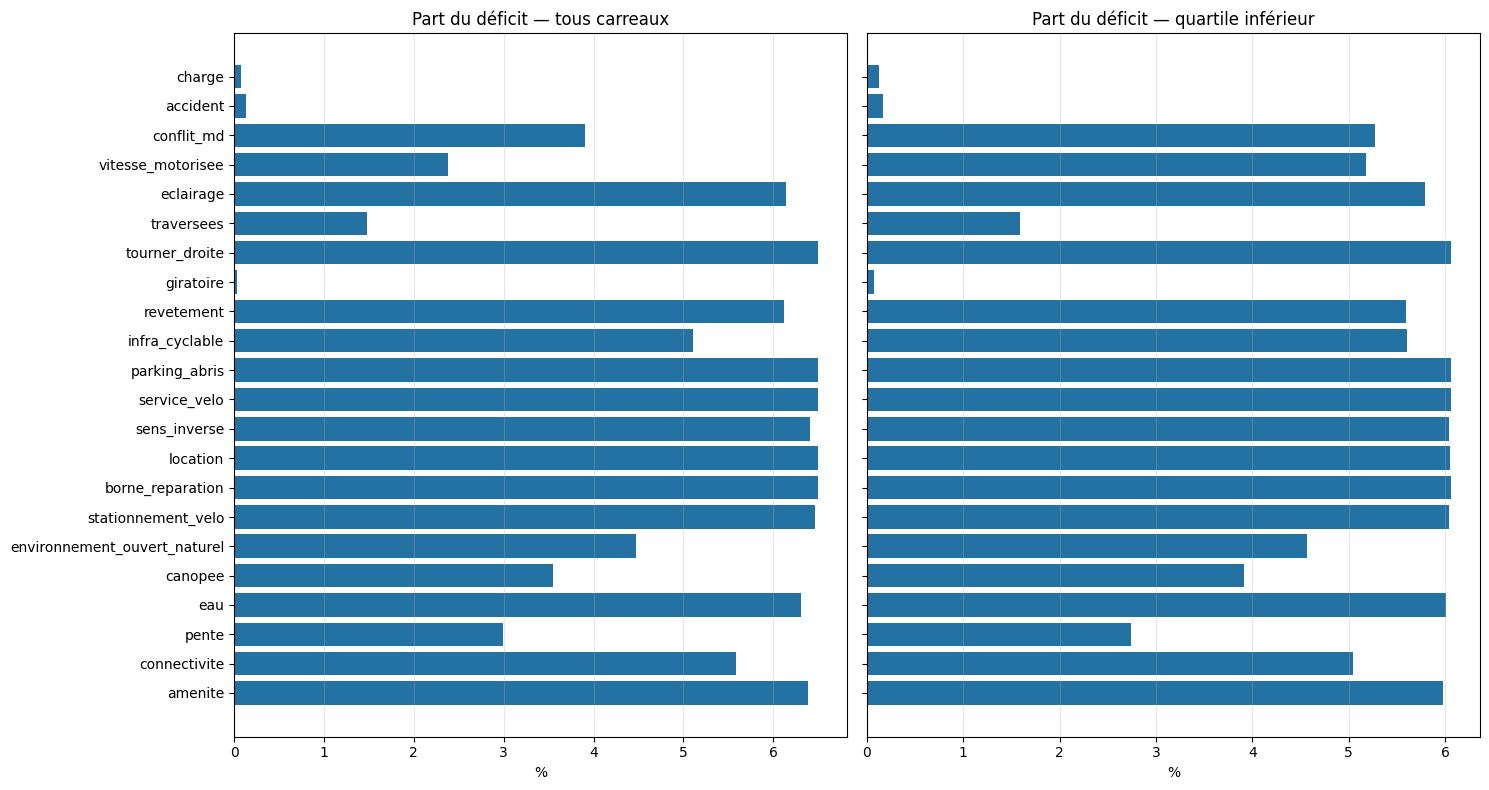

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(15, 8), sharey=True)
order4 = m4_index.index
grouped_barh(pd.DataFrame({k: m4_index[(k, "part_deficit_%")] for k in data}), "Part du déficit — tous carreaux", "%", ax=axes[0], order=order4)
grouped_barh(pd.DataFrame({k: m4_index[(k, "part_deficit_Q1_%")] for k in data}), "Part du déficit — quartile inférieur", "%", ax=axes[1], order=order4)
plt.tight_layout(); plt.savefig(OUT_DIR / "4_deficit_index.png", dpi=150); plt.show()

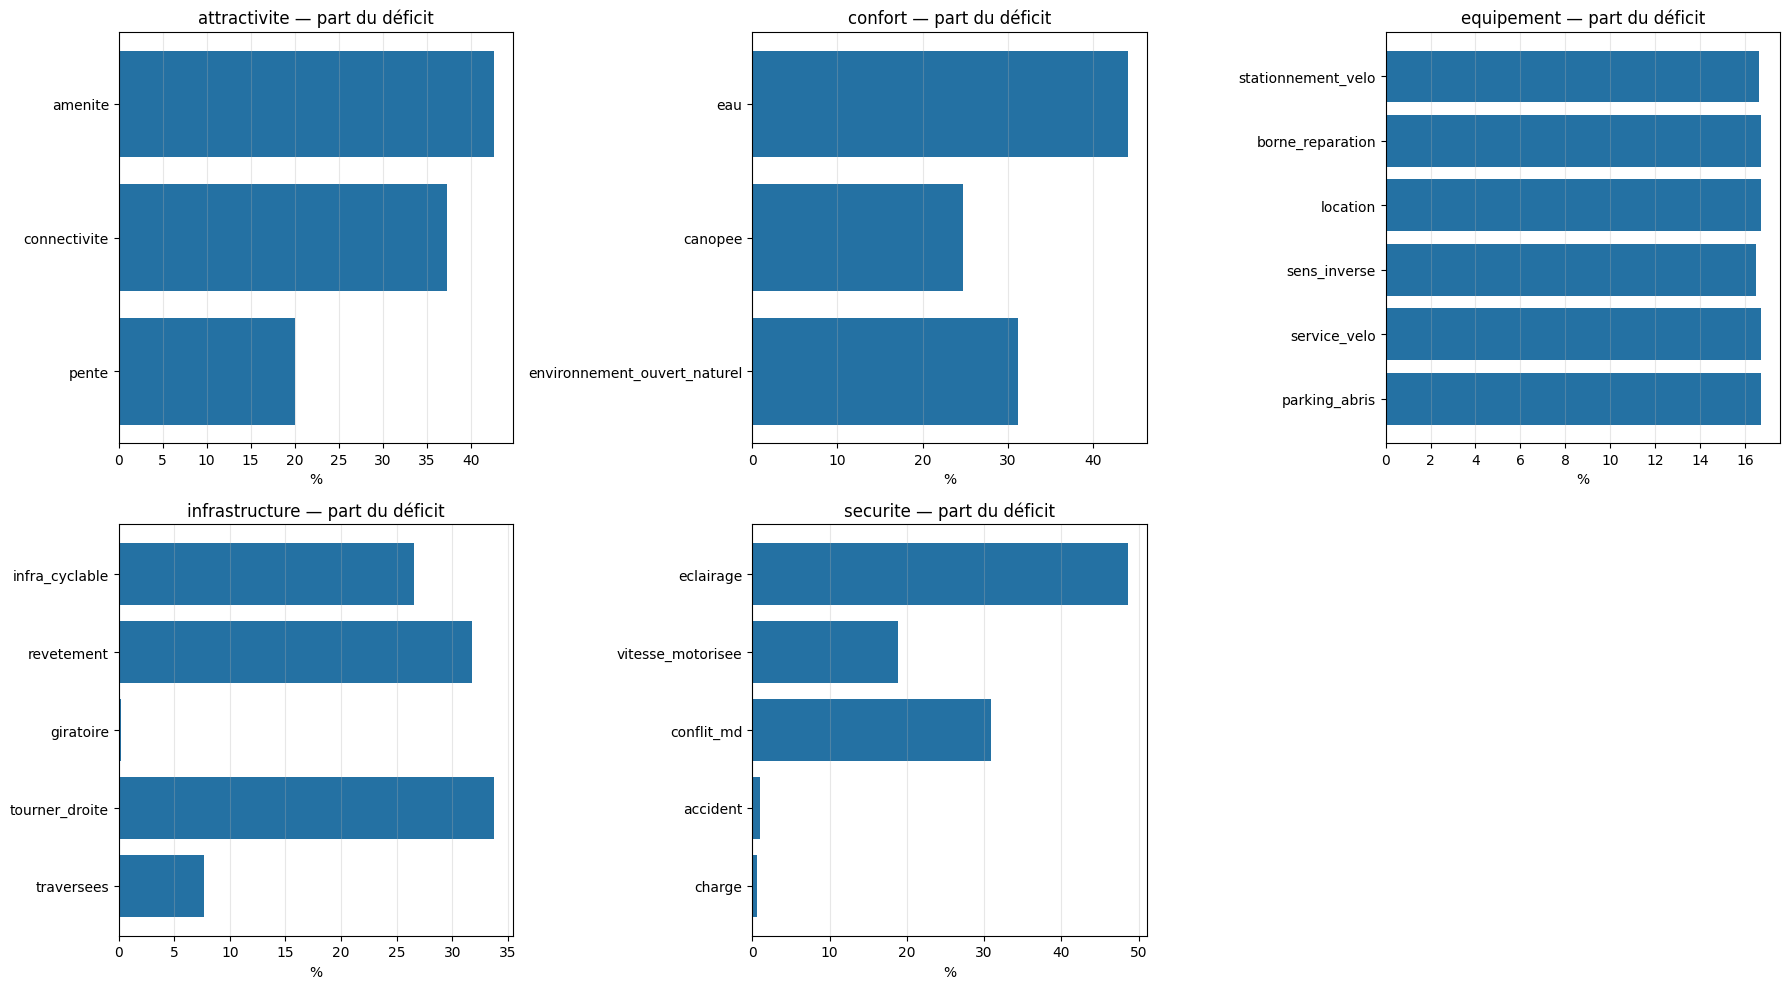


=== attractivite ===


GG                                                
             deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
amenite            0.328         42.676          0.333            37.523
connectivite       0.287         37.339          0.291            32.798
pente              0.153         19.985          0.264            29.678


=== confort ===


GG                                                
                             deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
eau                                0.324         44.043          0.331            38.248
canopee                            0.182         24.781          0.247            28.546
environnement_ouvert_naturel       0.229         31.176          0.287            33.206


=== equipement ===


GG                                                
                   deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
stationnement_velo       0.166         16.628          0.167            16.667
borne_reparation         0.167         16.720          0.167            16.667
location                 0.167         16.713          0.167            16.667
sens_inverse             0.164         16.495          0.167            16.667
service_velo             0.167         16.725          0.167            16.667
parking_abris            0.167         16.719          0.167            16.667


=== infrastructure ===


GG                                                
               deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
infra_cyclable       0.157         26.530          0.172            25.665
revetement           0.188         31.809          0.193            28.805
giratoire            0.001          0.189          0.002             0.261
tourner_droite       0.200         33.783          0.200            29.839
traversees           0.046          7.689          0.103            15.430


=== securite ===


GG                                                
                  deficit_moy part_deficit_% deficit_moy_Q1 part_deficit_Q1_%
eclairage               0.189         48.570          0.189            33.110
vitesse_motorisee       0.073         18.816          0.181            31.649
conflit_md              0.120         30.931          0.185            32.478
accident                0.004          1.042          0.011             1.911
charge                  0.002          0.641          0.005             0.853

In [49]:
m4_class = {}
fig, axes = class_axes(len(CLASSES))
for ax, c in zip(axes, CLASSES):
    t = {k: deficit_table(d, "class", c) for k, d in data.items() if c in d["classes"]}
    t = {k: v for k, v in t.items() if v is not None}
    m4_class[c] = pd.concat(t, axis=1)
    grouped_barh(pd.DataFrame({k: m4_class[c][(k, "part_deficit_%")] for k in t}), f"{c} — part du déficit", "%", ax=ax)
plt.tight_layout(); plt.savefig(OUT_DIR / "4_deficit_classes.png", dpi=150); plt.show()
for c in CLASSES:
    print(f"\n=== {c} ==="); display(m4_class[c])

## 5. Corrélations de Spearman

Corrélation de rang entre chaque attribut et chaque score (classes + indice). Robuste aux distributions très asymétriques. Les attributs à poids 0 dans l'indice (en gris) sont inclus pour voir s'ils sont redondants avec ceux qui pèsent.

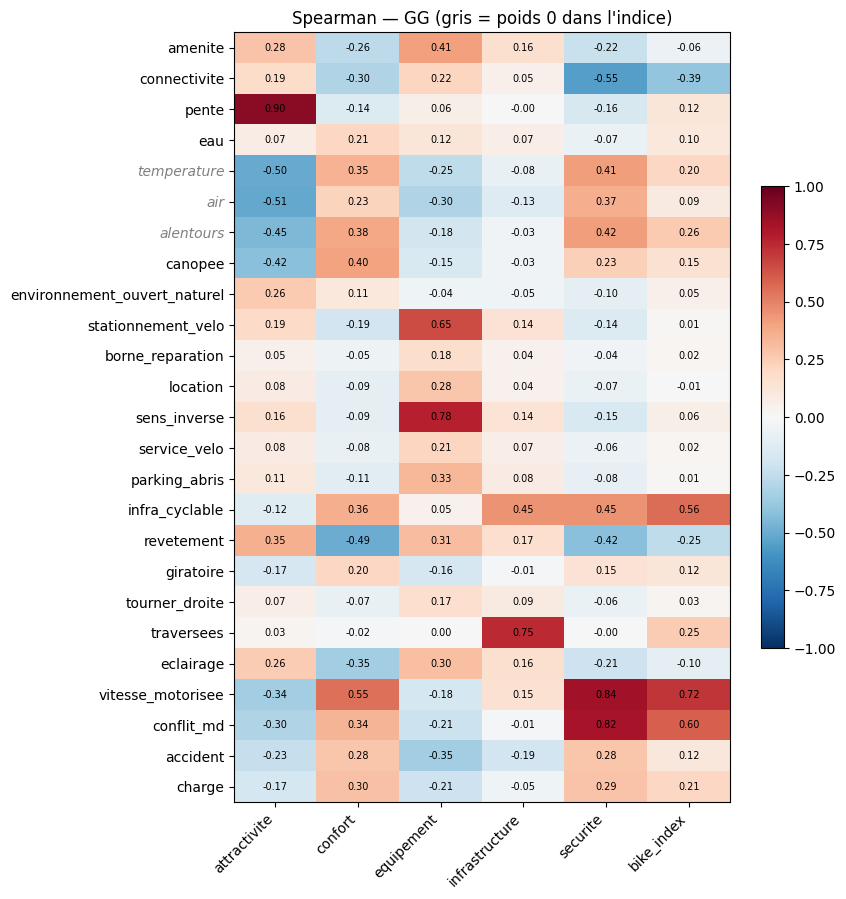

GG                                                      
                             attractivite confort equipement infrastructure securite bike_index
amenite                             0.284  -0.264      0.412          0.159   -0.221     -0.062
connectivite                        0.185  -0.303      0.218          0.048   -0.550     -0.393
pente                               0.903  -0.137      0.058         -0.003   -0.157      0.120
eau                                 0.073   0.207      0.118          0.070   -0.068      0.104
temperature                        -0.504   0.347     -0.252         -0.077    0.415      0.205
air                                -0.514   0.226     -0.301         -0.131    0.367      0.092
alentours                          -0.451   0.385     -0.181         -0.033    0.419      0.263
canopee                            -0.417   0.399     -0.153         -0.032    0.235      0.155
environnement_ouvert_naturel        0.260   0.109     -0.042         -0.046   -0.099      0.050
stationnement_velo                  0.188  -0.192      0.650          0.143   -0.140      0.015
borne_reparation                    0.049  -0.051      0.179          0.044   -0.035      0.018
location                            0.083  -0.088      0.280          0.042   -0.066     -0.007
sens_inverse                        0.161  -0.090      0.776          0.141   -0.152      0.061
service_velo                        0.079  -0.077      0.214          0.068   -0.060      0.019
parking_abris                       0.106  -0.113      0.333          0.083   -0.080      0.012
infra_cyclable                     -0.123   0.361      0.046          0.446    0.448      0.557
revetement                          0.354  -0.495      0.312          0.168   -0.416     -0.252
giratoire                          -0.172   0.204     -0.164         -0.011    0.148      0.119
tourner_droite                      0.070  -0.071      0.165          0.087   -0.064      0.026
traversees                          0.025  -0.021      0.004          0.750   -0.001      0.251
eclairage                           0.256  -0.346      0.302          0.163   -0.209     -0.096
vitesse_motorisee                  -0.344   0.551     -0.179          0.153    0.841      0.716
conflit_md                         -0.302   0.343     -0.213         -0.013    0.823      0.598
accident                           -0.232   0.279     -0.346         -0.190    0.279      0.117
charge                             -0.174   0.296     -0.209         -0.045    0.286      0.206

In [50]:
def spearman_matrix(d):
    df = d["df"]
    targets = {**{c: d["class_cols"][c] for c in d["classes"]}, d["index_col"]: d["index_col"]}
    attrs = class_order(d["weights"].index, FIRST)
    return pd.DataFrame({t: [stats.spearmanr(df[a], df[col]).statistic for a in attrs] for t, col in targets.items()}, index=attrs)


m5 = {k: spearman_matrix(d) for k, d in data.items()}
fig, axes = plt.subplots(1, len(m5), figsize=(8 * len(m5), 10), squeeze=False)
for ax, (k, M) in zip(axes[0], m5.items()):
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(M.shape[1]), M.columns, rotation=45, ha="right"); ax.set_yticks(range(M.shape[0]), M.index)
    w = data[k]["weights"]
    for lbl in ax.get_yticklabels():
        if w.loc[lbl.get_text(), "initial_weight"] == 0: lbl.set_color("grey"); lbl.set_style("italic")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
    ax.set_title(f"Spearman — {k} (gris = poids 0 dans l'indice)")
fig.colorbar(im, ax=axes, shrink=.6)
plt.savefig(OUT_DIR / "5_spearman.png", dpi=150, bbox_inches="tight"); plt.show()
pd.concat(m5, axis=1)

## 6. Indice pondéré vs indice non pondéré

`3_1` exporte aussi `bike_index_unweighted` : même calcul avec **un poids de 1 pour chaque attribut inclus**, y compris ceux à `initial_weight = 0`. On compare :
- l'accord entre les deux classements de carreaux (Spearman, et part des carreaux qui changent de quintile) ;
- la part de variance de chaque attribut dans l'un et l'autre indice. Si elles sont proches, les poids changent peu le résultat : c'est la distribution des attributs qui domine.

[GG] Spearman pondéré / non pondéré = 0.817 | carreaux qui changent de quintile : 52.9%


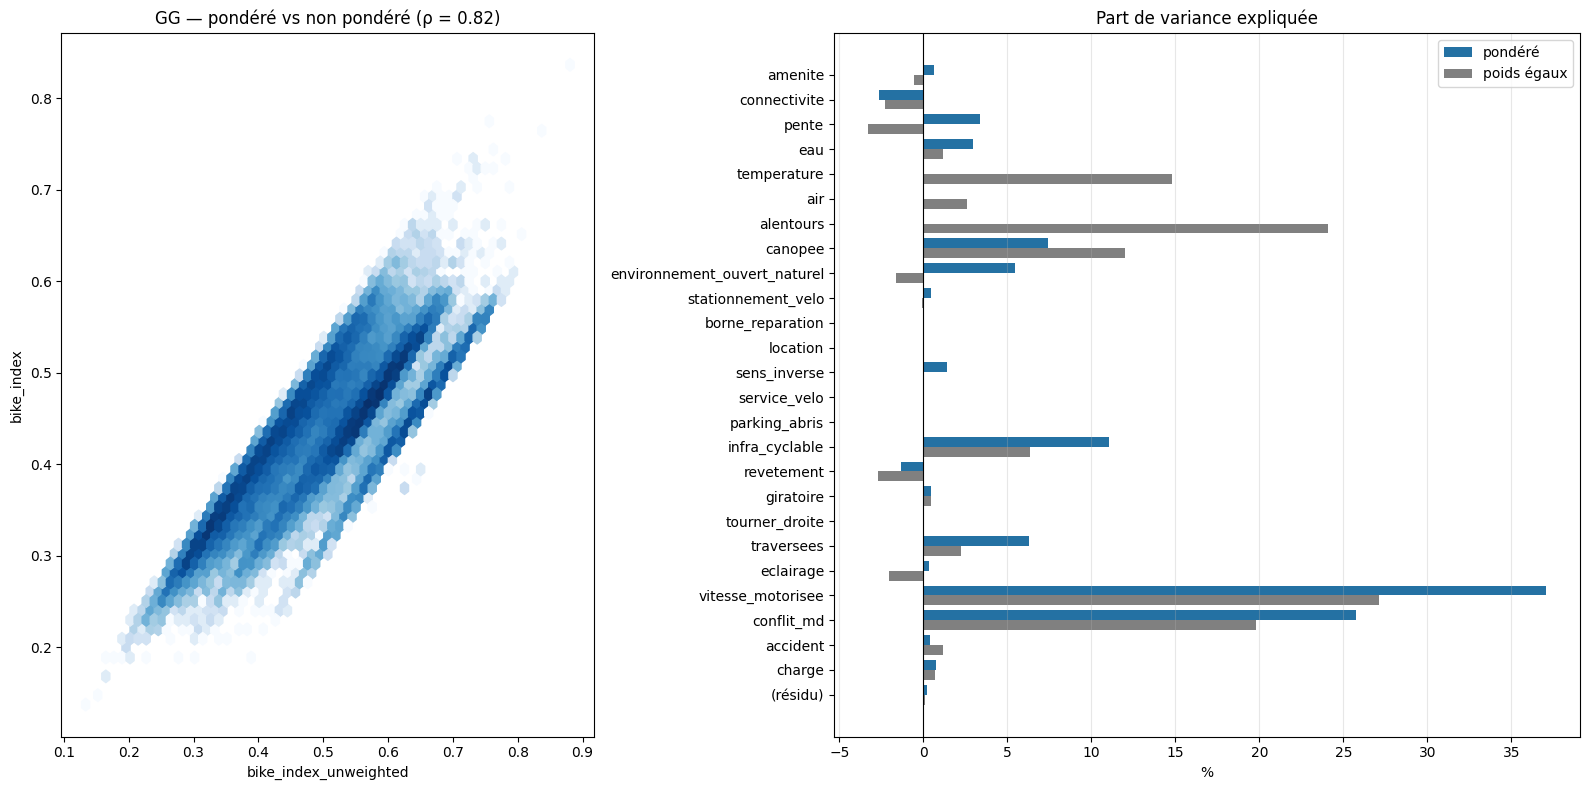

,poids_nominal_%,poids_egal_%,part_variance_pondere_%,part_variance_non_pondere_%
amenite,4.545,4.000,0.619,-0.545
connectivite,4.545,4.000,-2.648,-2.297
pente,4.545,4.000,3.352,-3.303
eau,4.545,4.000,2.939,1.177
temperature,NaN,4.000,NaN,14.768
air,NaN,4.000,NaN,2.620
alentours,NaN,4.000,NaN,24.100
canopee,4.545,4.000,7.406,12.025
environnement_ouvert_naturel,4.545,4.000,5.455,-1.619
stationnement_velo,4.545,4.000,0.466,-0.059


In [51]:
m6 = {}
for k, d in data.items():
    df = d["df"]
    if UNWEIGHTED_COL not in df:
        print(f"[{k}] pas de colonne {UNWEIGHTED_COL} : section ignorée")
        continue
    y_w, y_u = df[d["index_col"]], df[UNWEIGHTED_COL]
    rho = stats.spearmanr(y_w, y_u).statistic
    q_w, q_u = pd.qcut(y_w, 5, labels=False), pd.qcut(y_u, 5, labels=False)
    print(f"[{k}] Spearman pondéré / non pondéré = {rho:.3f} | carreaux qui changent de quintile : {(q_w != q_u).mean():.1%}")

    attrs = list(d["weights"].index)
    cb_u = df[attrs] / len(attrs)
    a, b = calibrate(y_u, cb_u.sum(axis=1))
    m6[k] = pd.DataFrame({
        "poids_nominal_%": nominal_share(d, "index"),
        "poids_egal_%": pd.Series(100 / len(attrs), index=attrs),
        "part_variance_pondere_%": m3_index[k]["part_variance_%"],
        "part_variance_non_pondere_%": variance_decomp(cb_u, y_u, a, b),
    })
    m6[k] = m6[k].loc[class_order([i for i in m6[k].index if i != "(résidu)"], FIRST) + ["(résidu)"]]

    fig, axes = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1.4]})
    axes[0].hexbin(y_u, y_w, gridsize=60, bins="log", cmap="Blues", mincnt=1)
    axes[0].set_xlabel(UNWEIGHTED_COL); axes[0].set_ylabel(d["index_col"])
    axes[0].set_title(f"{k} — pondéré vs non pondéré (ρ = {rho:.2f})")
    tab = m6[k][["part_variance_pondere_%", "part_variance_non_pondere_%"]].fillna(0)
    yy = np.arange(len(tab)); h = .4
    axes[1].barh(yy - h / 2, tab.iloc[:, 0], height=h, label="pondéré", color=COLORS[k])
    axes[1].barh(yy + h / 2, tab.iloc[:, 1], height=h, label="poids égaux", color="grey")
    axes[1].set_yticks(yy, tab.index); axes[1].invert_yaxis(); axes[1].axvline(0, color="k", lw=.8)
    axes[1].set_title("Part de variance expliquée"); axes[1].set_xlabel("%"); axes[1].legend(); axes[1].grid(axis="x", alpha=.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"6_pondere_vs_non_pondere_{k}.png", dpi=150); plt.show()
    display(m6[k])

## 7. Classe « fondamental » (infrastructure + sécurité)

Classe construite ici, qui regroupe **tous les attributs** des classes `infrastructure` et `securite`, avec leur `class_weight` :

$$F = \frac{\sum_{a \in \text{infra} \cup \text{sécu}} w^{class}_a\,x_a}{\sum_{a \in \text{infra} \cup \text{sécu}} w^{class}_a}$$

$F$ est sur l'échelle des attributs : 1 = carreau parfait sur tous ces attributs, 0 = pire valeur partout. Avec `FONDAMENTAL_MINMAX = True`, on la ramène en plus sur [0, 1] par min-max, comme les colonnes `Classe_*` de `3_1`. Attention : ce min-max est fait sur les carreaux, alors que `3_1` le fait sur les tronçons. Les deux échelles ne sont donc pas strictement identiques.

On visualise :
1. la composition de la classe (poids de chaque attribut) ;
2. sa distribution, comparée à celles de `Classe_infrastructure`, `Classe_securite` et du bike index ;
3. ce qui fait varier $F$ d'un carreau à l'autre : décomposition de variance exacte, puisque $F$ est construite ici et n'a pas de résidu ;
4. son lien avec le bike index.

[GG] classe fondamental : 10 attributs (infrastructure, securite)


,classe_origine,class_weight,poids_dans_fondamental_%
attribute,,,
infra_cyclable,infrastructure,0.500,10.000
revetement,infrastructure,0.500,10.000
giratoire,infrastructure,0.500,10.000
tourner_droite,infrastructure,0.500,10.000
traversees,infrastructure,0.500,10.000
eclairage,securite,0.500,10.000
vitesse_motorisee,securite,0.500,10.000
conflit_md,securite,0.500,10.000
accident,securite,0.500,10.000


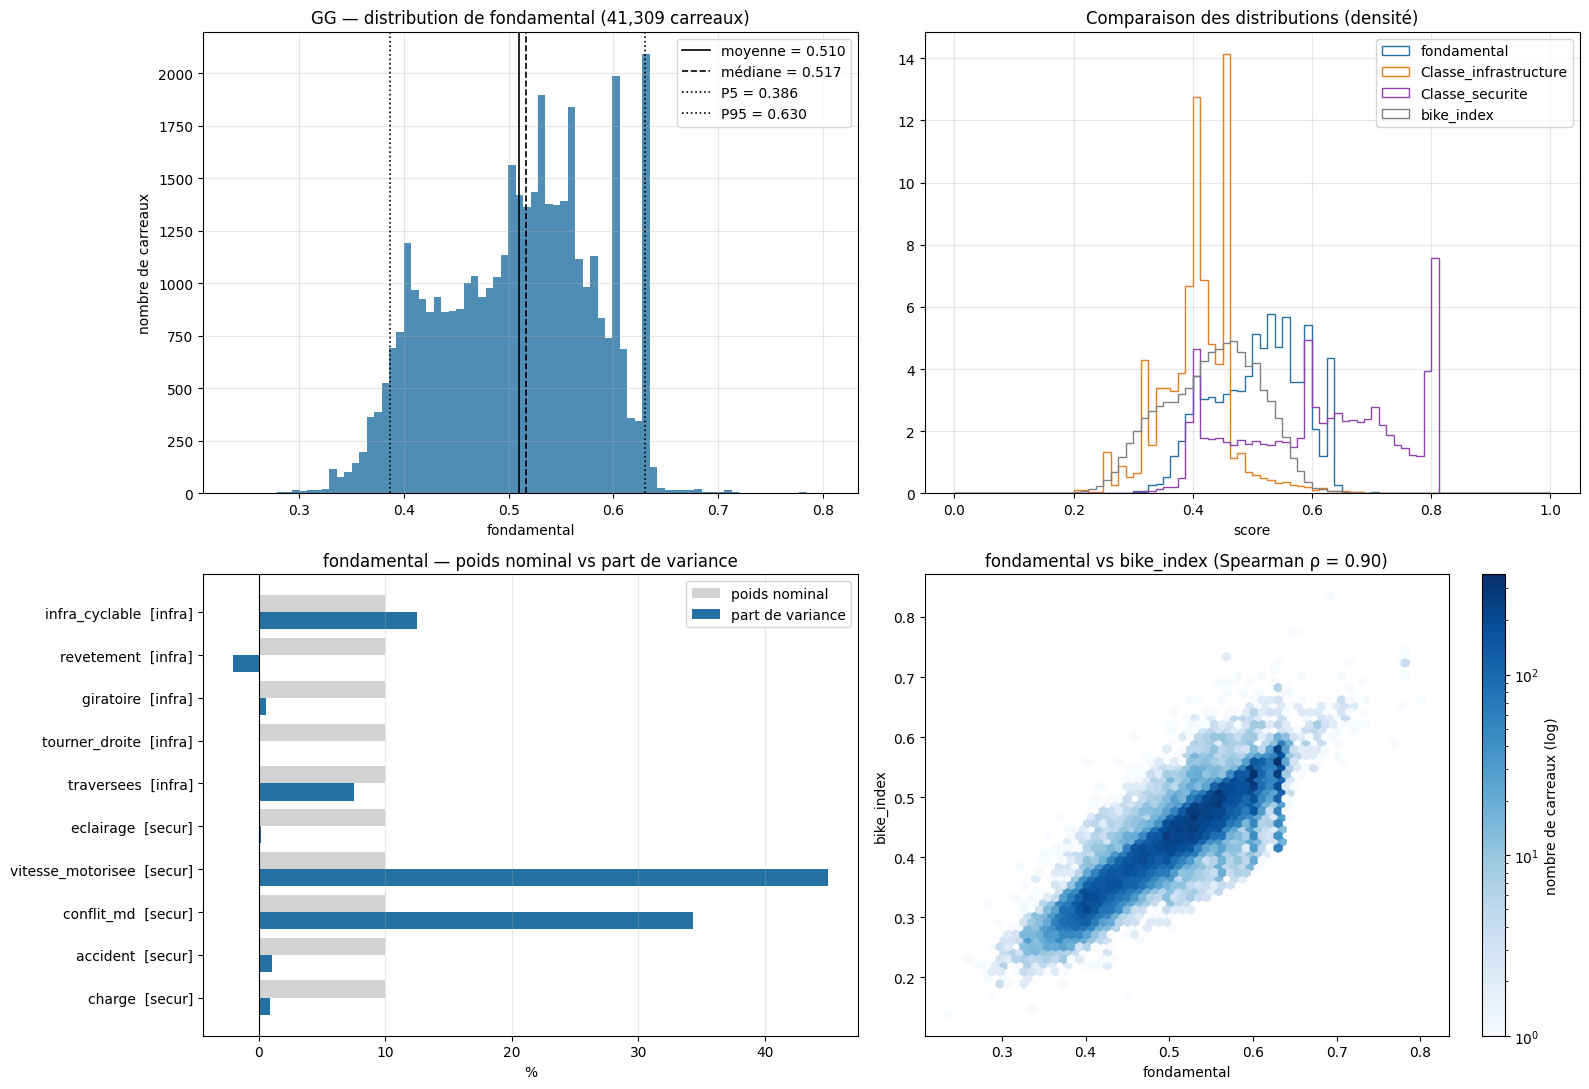

Statistiques de distribution :


,mean,std,min,P5,P25,median,P75,P95,max,IQR,skew,%au_mode (arrondi 0.01)
fondamental,0.510,0.074,0.236,0.386,0.452,0.517,0.565,0.630,0.806,0.114,-0.206,6.086
Classe_infrastructure,0.408,0.062,0.168,0.312,0.375,0.405,0.454,0.493,0.780,0.078,0.177,17.345
Classe_securite,0.611,0.133,0.148,0.400,0.499,0.616,0.719,0.800,1.000,0.220,-0.169,13.312
bike_index,0.433,0.080,0.137,0.297,0.374,0.439,0.492,0.554,0.837,0.118,-0.153,5.084


Décomposition de variance de la classe fondamental :


,classe_origine,poids_nominal_%,part_variance_%,%zero
infra_cyclable,infrastructure,10.000,12.471,20.497
revetement,infrastructure,10.000,-2.067,59.275
giratoire,infrastructure,10.000,0.540,0.007
tourner_droite,infrastructure,10.000,0.006,99.717
traversees,infrastructure,10.000,7.561,1.022
eclairage,securite,10.000,0.187,89.155
vitesse_motorisee,securite,10.000,45.033,17.807
conflit_md,securite,10.000,34.349,21.511
accident,securite,10.000,1.029,0.058
charge,securite,10.000,0.891,0.034


Par classe d'origine :


,poids_nominal_%,part_variance_%
classe_origine,,
infrastructure,50.000,18.511
securite,50.000,81.489


In [52]:
FONDAMENTAL_CLASSES = ["infrastructure", "securite"]
FONDAMENTAL_MINMAX = False   # True : ramène F sur [0, 1] (min-max sur les carreaux)

m7 = {}
for k, d in data.items():
    df, w = d["df"], d["weights"]
    sub = [c for c in FONDAMENTAL_CLASSES if c in d["classes"]]
    ws = w[w["Class"].isin(sub) & (w["class_weight"] > 0)]["class_weight"]
    ws = ws.loc[class_order(ws.index, FIRST)]
    cb = df[ws.index] * (ws / ws.sum()).values          # contributions c_a, somme = F
    F = cb.sum(axis=1)
    if FONDAMENTAL_MINMAX:
        cb = cb / (F.max() - F.min())
        F = (F - F.min()) / (F.max() - F.min())
    df["fondamental"] = F
    lab_F = "fondamental" + (" (min-max)" if FONDAMENTAL_MINMAX else "")

    # --- 1. composition
    compo = pd.DataFrame({"classe_origine": w.loc[ws.index, "Class"], "class_weight": ws,
                          "poids_dans_fondamental_%": ws / ws.sum() * 100})
    print(f"[{k}] classe fondamental : {len(ws)} attributs ({', '.join(sub)})")
    display(compo)

    # --- 2. distribution
    series = {lab_F: F, **{f"Classe_{c}": df[d["class_cols"][c]] for c in sub}, d["index_col"]: df[d["index_col"]]}
    def stats_row(s):
        q = s.quantile([.05, .25, .5, .75, .95])
        return {"mean": s.mean(), "std": s.std(), "min": s.min(), "P5": q[.05], "P25": q[.25], "median": q[.5],
                "P75": q[.75], "P95": q[.95], "max": s.max(), "IQR": q[.75] - q[.25],
                "skew": s.skew(), "%au_mode (arrondi 0.01)": s.round(2).value_counts(normalize=True).iloc[0] * 100}
    dist = pd.DataFrame({n: stats_row(s) for n, s in series.items()}).T

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    ax = axes[0, 0]
    ax.hist(F, bins=80, color=COLORS[k], alpha=.8)
    for v, ls, lbl in [(F.mean(), "-", "moyenne"), (F.median(), "--", "médiane"),
                       (F.quantile(.05), ":", "P5"), (F.quantile(.95), ":", "P95")]:
        ax.axvline(v, color="k", ls=ls, lw=1.2, label=f"{lbl} = {v:.3f}")
    ax.set_title(f"{k} — distribution de {lab_F} ({len(F):,} carreaux)")
    ax.set_xlabel(lab_F); ax.set_ylabel("nombre de carreaux"); ax.legend(); ax.grid(alpha=.3)

    ax = axes[0, 1]
    bins = np.linspace(0, 1, 81)
    for (n, s), col in zip(series.items(), [COLORS[k], "#e67e22", "#8e44ad", "grey"]):
        ax.hist(s, bins=bins, histtype="step", lw=2 if n == lab_F else 1.3, density=True, label=n, color=col)
    ax.set_title("Comparaison des distributions (densité)"); ax.set_xlabel("score"); ax.legend(); ax.grid(alpha=.3)

    # --- 3. décomposition de variance (exacte : F est la somme des c_a)
    var_F = variance_decomp(cb, F).drop("(résidu)")
    nom = compo["poids_dans_fondamental_%"]
    ax = axes[1, 0]
    yy = np.arange(len(var_F)); h = .4
    ax.barh(yy - h / 2, nom.reindex(var_F.index), height=h, color="lightgrey", label="poids nominal")
    ax.barh(yy + h / 2, var_F, height=h, color=COLORS[k], label="part de variance")
    ax.set_yticks(yy, [f"{a}  [{compo.loc[a, 'classe_origine'][:5]}]" for a in var_F.index]); ax.invert_yaxis()
    ax.axvline(0, color="k", lw=.8); ax.set_xlabel("%"); ax.legend(); ax.grid(axis="x", alpha=.3)
    ax.set_title("fondamental — poids nominal vs part de variance")

    # --- 4. lien avec le bike index
    ax = axes[1, 1]
    rho = stats.spearmanr(F, df[d["index_col"]]).statistic
    hb = ax.hexbin(F, df[d["index_col"]], gridsize=60, bins="log", cmap="Blues", mincnt=1)
    fig.colorbar(hb, ax=ax, label="nombre de carreaux (log)")
    ax.set_xlabel(lab_F); ax.set_ylabel(d["index_col"]); ax.set_title(f"fondamental vs {d['index_col']} (Spearman ρ = {rho:.2f})")
    plt.tight_layout(); plt.savefig(OUT_DIR / f"7_fondamental_{k}.png", dpi=150); plt.show()

    print("Statistiques de distribution :"); display(dist)
    var_tab = pd.DataFrame({"classe_origine": compo["classe_origine"], "poids_nominal_%": nom, "part_variance_%": var_F,
                            "%zero": (df[ws.index] == 0).mean() * 100})
    print("Décomposition de variance de la classe fondamental :"); display(var_tab)
    part_cls = var_tab.groupby("classe_origine")[["poids_nominal_%", "part_variance_%"]].sum()
    print("Par classe d'origine :"); display(part_cls)
    m7[k] = {"composition": compo, "distribution": dist, "variance": var_tab, "par_classe": part_cls}

## Synthèse et export

Un tableau par layer : pour chaque attribut, ses métriques dans le bike index, avec des **alertes** automatiques :
- `quasi mort` : poids > 0 mais > 90 % de carreaux à 0 ;
- `sous-représenté` : part du score moyen < 25 % de son poids nominal ;
- `classe seulement` / `indice seulement` : l'attribut compte à un seul des deux niveaux ;
- `sens inverse` : corrélation de Spearman avec l'indice < −0,05.

Export Excel dans `OUT_DIR` (un onglet par niveau).

In [53]:
def alerts(row):
    a = []
    if row["poids_nominal_%"] > 0 and row["%zero"] > 90: a.append("quasi mort")
    if row["poids_nominal_%"] > 0 and row["part_score_moy_%"] < .25 * row["poids_nominal_%"]: a.append("sous-représenté")
    if row["poids_classe"] > 0 and not row["poids_nominal_%"] > 0: a.append("classe seulement")
    if row["poids_classe"] == 0 and row["poids_nominal_%"] > 0: a.append("indice seulement")
    if row["spearman_index"] < -0.05: a.append("sens inverse")
    return ", ".join(a)


synth = {}
for k, d in data.items():
    s = pd.concat([
        desc[k][["classe", "poids_classe", "%zero", "%one", "P5-P95"]],
        m2_index[k][["poids_nominal_%", "part_%"]].rename(columns={"part_%": "part_score_moy_%"}),
        m3_index[k][["part_variance_%", "poids_effectif_OLS_%"]].drop(index="(résidu)", errors="ignore"),
        m4_index[k][["part_deficit_%", "part_deficit_Q1_%"]],
        m5[k][[d["index_col"]]].rename(columns={d["index_col"]: "spearman_index"}),
    ], axis=1)
    s["poids_nominal_%"] = s["poids_nominal_%"].fillna(0)
    s["alertes"] = s.apply(alerts, axis=1)
    synth[k] = s.loc[class_order(s.index, FIRST)]
synth_cmp = pd.concat(synth, axis=1)
display(synth_cmp)

for k, s in synth.items():
    flagged = s[s["alertes"] != ""]
    print(f"\n[{k}] {len(flagged)} attribut(s) avec alerte :")
    for a, r in flagged.iterrows():
        print(f"  - {a:30s} ({r['classe']}) : {r['alertes']}")

GG                                                                                                                                                          \
                                      classe poids_classe  %zero   %one P5-P95 poids_nominal_% part_score_moy_% part_variance_% poids_effectif_OLS_% part_deficit_% part_deficit_Q1_% spearman_index   
amenite                         attractivite        0.500 94.372  0.153  0.023           4.545            0.258           0.619                4.537          6.386             5.974         -0.062   
connectivite                    attractivite        0.500  0.065  0.000  0.206           4.545            2.118          -2.648                4.537          5.588             5.049         -0.393   
pente                           attractivite        0.500  1.244  0.012  0.780           4.545            8.167           3.352                4.535          2.991             2.741          0.120   
eau                                  confort        0.500 93.764  0.833  0.112           4.545            0.429           2.939                4.526          6.312             6.008          0.104   
temperature                          confort        0.000  4.725 19.236  1.000           0.000              NaN             NaN                  NaN            NaN               NaN          0.205   
air                                  confort        0.000  0.000  0.027  0.254           0.000              NaN             NaN                  NaN            NaN               NaN          0.092   
alentours                            confort        0.000 16.287 24.084  1.000           0.000              NaN             NaN                  NaN            NaN               NaN          0.263   
canopee                              confort        0.500  6.800  1.716  0.963           4.545            6.860           7.406                4.540          3.552             3.907          0.155   
environnement_ouvert_naturel         confort        0.500 29.841  0.131  0.918           4.545            4.725           5.455                4.543          4.468             4.569          0.050   
stationnement_velo                equipement        0.500 97.337  0.017  0.000           4.545            0.090           0.466                4.510          6.458             6.042          0.015   
borne_reparation                  equipement        0.500 99.801  0.005  0.000           4.545            0.007           0.049                4.595          6.494             6.058          0.018   
location                          equipement        0.500 99.499  0.000  0.000           4.545            0.013           0.014                4.602          6.491             6.053         -0.007   
sens_inverse                      equipement        0.500 96.311  0.324  0.000           4.545            0.211           1.388                4.546          6.406             6.038          0.061   
service_velo                      equipement        0.500 99.710  0.000  0.000           4.545            0.002           0.010                4.468          6.496             6.059          0.019   
parking_abris                     equipement        0.500 99.300  0.000  0.000           4.545            0.008           0.036                4.597          6.493             6.058          0.012   
infra_cyclable                infrastructure        0.500 20.497  0.479  0.434           4.545            3.252          11.021                4.537          5.101             5.600          0.557   
revetement                    infrastructure        0.500 59.275  0.007  0.291           4.545            0.888          -1.325                4.557          6.116             5.596         -0.252   
giratoire                     infrastructure        0.500  0.007 96.935  0.000           4.545           15.049           0.470                4.548          0.036             0.069          0.119   
tourner_droite                infrastructu


[GG] 12 attribut(s) avec alerte :
  - amenite                        (attractivite) : quasi mort, sous-représenté, sens inverse
  - connectivite                   (attractivite) : sens inverse
  - eau                            (confort) : quasi mort, sous-représenté
  - stationnement_velo             (equipement) : quasi mort, sous-représenté
  - borne_reparation               (equipement) : quasi mort, sous-représenté
  - location                       (equipement) : quasi mort, sous-représenté
  - sens_inverse                   (equipement) : quasi mort, sous-représenté
  - service_velo                   (equipement) : quasi mort, sous-représenté
  - parking_abris                  (equipement) : quasi mort, sous-représenté
  - revetement                     (infrastructure) : sous-représenté, sens inverse
  - tourner_droite                 (infrastructure) : quasi mort, sous-représenté
  - eclairage                      (securite) : sous-représenté, sens inverse


In [54]:
xlsx_out = OUT_DIR / f"analyse_poids_attributs_{NETWORK}.xlsx"
with pd.ExcelWriter(xlsx_out) as xw:
    synth_cmp.to_excel(xw, sheet_name="synthese_index")
    fid.to_excel(xw, sheet_name="fidelite_reconstruction")
    m3_classes_to_index.to_excel(xw, sheet_name="classes_vers_index")
    for k, t in m6.items():
        t.to_excel(xw, sheet_name=f"pondere_vs_egal_{k}"[:31])
    for k, t in m7.items():
        sh = f"fondamental_{k}"[:31]
        r0 = 0
        for name in ["composition", "distribution", "variance", "par_classe"]:
            pd.DataFrame([[name]]).to_excel(xw, sheet_name=sh, startrow=r0, header=False, index=False)
            t[name].to_excel(xw, sheet_name=sh, startrow=r0 + 1)
            r0 += len(t[name]) + 4
    for c in CLASSES:
        pd.concat({"contrib": m2_class[c], "variance": m3_class[c], "deficit": m4_class[c]}, axis=1).to_excel(xw, sheet_name=c[:31])
        for k, r in cov_results.get(c, {}).items():
            sh = f"cov_{c[:10]}_{k}"[:31]
            r["table"].to_excel(xw, sheet_name=sh)
            r["M"].to_excel(xw, sheet_name=sh, startrow=len(r["table"]) + 3)
            r["cov"].to_excel(xw, sheet_name=sh, startrow=2 * len(r["table"]) + 6)
print("Exporté :", xlsx_out)

Exporté : /Users/maximiliantrique/Documents/GitHub/projet_pieton_gg/Data/output/bike/GG/etude_stat/analyse_poids_attributs_bike.xlsx
